In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Läs in vårt dataset
df = pd.read_csv("Life Expectancy Data.csv")

# Ta bort extra mellanslag från kolumnnamnen
df.columns = df.columns.str.strip()

# Visa de fem första raderna

df.head()


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [2]:

# Kontrollera datasetets storlek
print("Antal rader och kolumner:", df.shape)

# Visa kolumnnamn
print(df.columns.tolist())

# Kontrollera datatyper och saknade värden
df.info()


Antal rader och kolumner: (2938, 22)
['Country', 'Year', 'Status', 'Life expectancy', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling']
<class 'pandas.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   str    
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   str    
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol            

In [3]:

# Kontrollera antal saknade värden per kolumn
df.isnull().sum().sort_values(ascending=False)


Population                         652
Hepatitis B                        553
GDP                                448
Total expenditure                  226
Alcohol                            194
Income composition of resources    167
Schooling                          163
thinness  1-19 years                34
thinness 5-9 years                  34
BMI                                 34
Diphtheria                          19
Polio                               19
Life expectancy                     10
Adult Mortality                     10
infant deaths                        0
Status                               0
Country                              0
Year                                 0
under-five deaths                    0
Measles                              0
percentage expenditure               0
HIV/AIDS                             0
dtype: int64

In [4]:

# Beräkna andelen saknade värden i procent
missing_percent = (df.isnull().sum() / len(df)) * 100

# Visa resultatet sorterat från högst till lägst
missing_percent.sort_values(ascending=False).round(2)


Population                         22.19
Hepatitis B                        18.82
GDP                                15.25
Total expenditure                   7.69
Alcohol                             6.60
Income composition of resources     5.68
Schooling                           5.55
thinness  1-19 years                1.16
thinness 5-9 years                  1.16
BMI                                 1.16
Diphtheria                          0.65
Polio                               0.65
Life expectancy                     0.34
Adult Mortality                     0.34
infant deaths                       0.00
Status                              0.00
Country                             0.00
Year                                0.00
under-five deaths                   0.00
Measles                             0.00
percentage expenditure              0.00
HIV/AIDS                            0.00
dtype: float64

In [5]:

# Visa beskrivande statistik för alla numeriska kolumner
df.describe().round(2)


,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
count,2938.00,2928.00,2928.00,2938.00,2744.00,2938.00,2385.00,2938.00,2904.00,2938.00,2919.00,2712.00,2919.00,2938.00,2490.00,2.286000e+03,2904.00,2904.00,2771.00,2775.00
mean,2007.52,69.22,164.80,30.30,4.60,738.25,80.94,2419.59,38.32,42.04,82.55,5.94,82.32,1.74,7483.16,1.275338e+07,4.84,4.87,0.63,11.99
std,4.61,9.52,124.29,117.93,4.05,1987.91,25.07,11467.27,20.04,160.45,23.43,2.50,23.72,5.08,14270.17,6.101210e+07,4.42,4.51,0.21,3.36
min,2000.00,36.30,1.00,0.00,0.01,0.00,1.00,0.00,1.00,0.00,3.00,0.37,2.00,0.10,1.68,3.400000e+01,0.10,0.10,0.00,0.00
25%,2004.00,63.10,74.00,0.00,0.88,4.69,77.00,0.00,19.30,0.00,78.00,4.26,78.00,0.10,463.94,1.957932e+05,1.60,1.50,0.49,10.10
50%,2008.00,72.10,144.00,3.00,3.76,64.91,92.00,17.00,43.50,4.00,93.00,5.76,93.00,0.10,1766.95,1.386542e+06,3.30,3.30,0.68,12.30
75%,2012.00,75.70,228.00,22.00,7.70,441.53,97.00,360.25,56.20,28.00,97.00,7.49,97.00,0.80,5910.81,7.420359e+06,7.20,7.20,0.78,14.30
max,2015.00,89.00,723.00,1800.00,17.87,19479.91,99.00,212183.00,87.30,2500.00,99.00,17.60,99.00,50.60,119172.74,1.293859e+09,27.70,28.60,0.95,20.70


### Tolkning av beskrivande statistik

Datasetet innehåller 2 938 observationer från perioden 2000–2015.

Den genomsnittliga förväntade livslängden är 69,22 år, medan medianen är 72,10 år. Skillnaden tyder på att fördelningen är något vänsterskev.

BNP per capita visar stor variation mellan observationerna. Medelvärdet är cirka 7 483 USD medan medianen är cirka 1 767 USD, vilket tyder på en högerskev fördelning och förekomst av höga värden.

Även vuxendödligheten varierar kraftigt mellan olika observationer.

Dessa resultat motiverar en fortsatt undersökning av variablernas fördelningar och möjliga extremvärden innan datan används för maskininlärning.


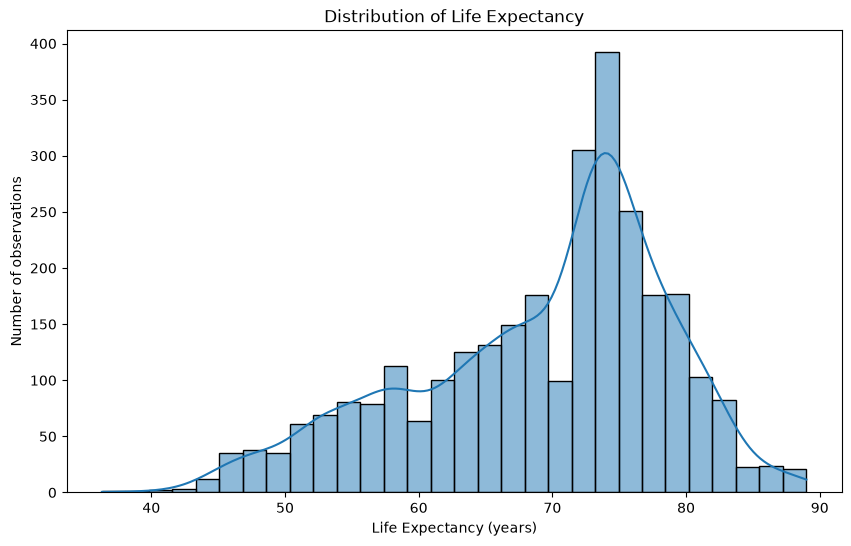

In [6]:

# Histogram över förväntad livslängd

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Life expectancy",
    bins=30,
    kde=True
)

plt.title("Distribution of Life Expectancy")
plt.xlabel("Life Expectancy (years)")
plt.ylabel("Number of observations")

plt.show()


### Tolkning av histogram – Life Expectancy

Histogrammet visar fördelningen av förväntad livslängd i datasetet under perioden 2000–2015.

De flesta observationerna ligger omkring 70–80 år, med den högsta koncentrationen runt 73–75 år.

Fördelningen är vänsterskev, vilket innebär att den har en längre svans mot lägre livslängder. Detta stöds av att medelvärdet (69,22 år) är lägre än medianen (72,10 år).

Histogrammet visar också att observationer med mycket låg eller mycket hög förväntad livslängd är mindre vanliga.

Analysen hjälper oss att förstå målvariabelns fördelning inför den fortsatta statistiska analysen och maskininlärningen.

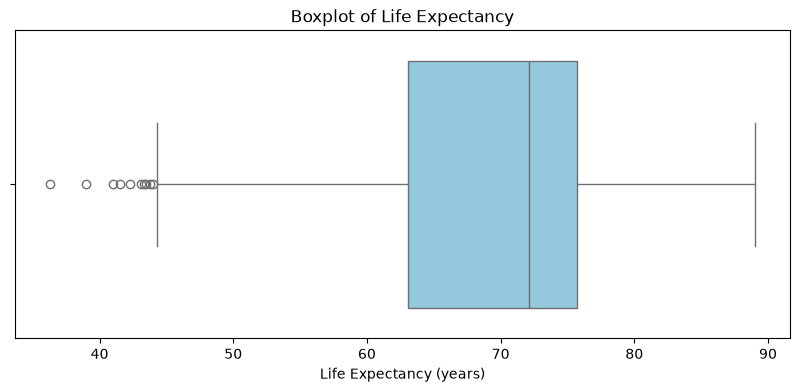

In [7]:

# Boxplot över förväntad livslängd

plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df,
    x="Life expectancy",
    color="skyblue"
)

plt.title("Boxplot of Life Expectancy")
plt.xlabel("Life Expectancy (years)")

plt.show()


### Boxplot – analys av extremvärden

Syftet med boxploten är att undersöka spridningen i förväntad livslängd och identifiera möjliga extremvärden. Diagrammet visar medianen, kvartilerna och observationer som ligger utanför de vanliga gränserna.

Eventuella extremvärden behöver undersökas innan beslut fattas om datarensning.

### Resultat och tolkning – Boxplot

Boxploten visar att medianen för förväntad livslängd är 72,1 år och att de mittersta 50 procenten av observationerna ligger mellan 63,1 och 75,7 år.

Diagrammet visar flera möjliga extremvärden under cirka 44,2 år, medan inga extremvärden förekommer över den övre gränsen.

Fördelningen har en längre svans mot lägre livslängder, vilket överensstämmer med histogrammet och indikerar en vänsterskev fördelning.

Extremvärdena kommer att undersökas vidare innan beslut fattas om eventuell datarensning, eftersom de kan representera verkliga skillnader i livslängd mellan länder.

In [8]:

# Beräkna kvartiler och IQR
Q1 = df["Life expectancy"].quantile(0.25)
Q3 = df["Life expectancy"].quantile(0.75)

IQR = Q3 - Q1

# Beräkna gränser för extremvärden
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filtrera fram observationer utanför gränserna
outliers = df[
    (df["Life expectancy"] < lower_bound) |
    (df["Life expectancy"] > upper_bound)
]

# Visa land, år och förväntad livslängd
outliers[["Country", "Year", "Life expectancy"]].sort_values(
    "Life expectancy"
)


,Country,Year,Life expectancy
1127,Haiti,2010,36.3
2312,Sierra Leone,2000,39.0
2311,Sierra Leone,2001,41.0
2309,Sierra Leone,2003,41.5
2308,Sierra Leone,2004,42.3
1585,Malawi,2000,43.1
2307,Sierra Leone,2005,43.3
1584,Malawi,2001,43.5
2921,Zambia,2000,43.8
1583,Malawi,2002,44.0


### Analys av extremvärden

Med hjälp av IQR-metoden identifierades 10 observationer med ovanligt låg förväntad livslängd.

Det lägsta värdet är Haiti år 2010 med 36,3 år. Andra länder som förekommer bland extremvärdena är Sierra Leone, Malawi och Zambia.

Flera av observationerna kommer från början av 2000-talet. De kan spegla verkliga skillnader i hälsa och levnadsförhållanden mellan länder.

Dessa observationer behålls tills vidare eftersom extremvärden inte automatiskt innebär felaktiga data. Deras tillförlitlighet och eventuella påverkan på maskininlärningsmodellerna behöver undersökas vidare.

In [9]:

# Välj numeriska kolumner
numeric_df = df.select_dtypes(include="number")

# Beräkna korrelation med Life expectancy
correlation = numeric_df.corr()["Life expectancy"]

# Sortera från högsta till lägsta korrelation
correlation.sort_values(ascending=False).round(2)


Life expectancy                    1.00
Schooling                          0.75
Income composition of resources    0.72
BMI                                0.57
Diphtheria                         0.48
Polio                              0.47
GDP                                0.46
Alcohol                            0.40
percentage expenditure             0.38
Hepatitis B                        0.26
Total expenditure                  0.22
Year                               0.17
Population                        -0.02
Measles                           -0.16
infant deaths                     -0.20
under-five deaths                 -0.22
thinness 5-9 years                -0.47
thinness  1-19 years              -0.48
HIV/AIDS                          -0.56
Adult Mortality                   -0.70
Name: Life expectancy, dtype: float64

### Tolkning av korrelationsanalys

Korrelationsanalysen visar att utbildning (Schooling, r = 0,75) och inkomstrelaterad utveckling (Income composition of resources, r = 0,72) har de starkaste positiva linjära sambanden med förväntad livslängd.

Vuxendödlighet (Adult Mortality, r = −0,70) och HIV/AIDS (r = −0,56) har starka negativa samband.

Befolkningsstorlek (Population, r = −0,02) visar däremot nästan inget linjärt samband med förväntad livslängd.

Resultaten visar vilka variabler som kan vara relevanta för den fortsatta analysen och modellutvecklingen. Korrelation innebär dock inte kausalitet, och sambanden behöver undersökas vidare.

Det är också viktigt att ta hänsyn till möjliga överlappningar mellan variablerna och att samma länder förekommer under flera år.

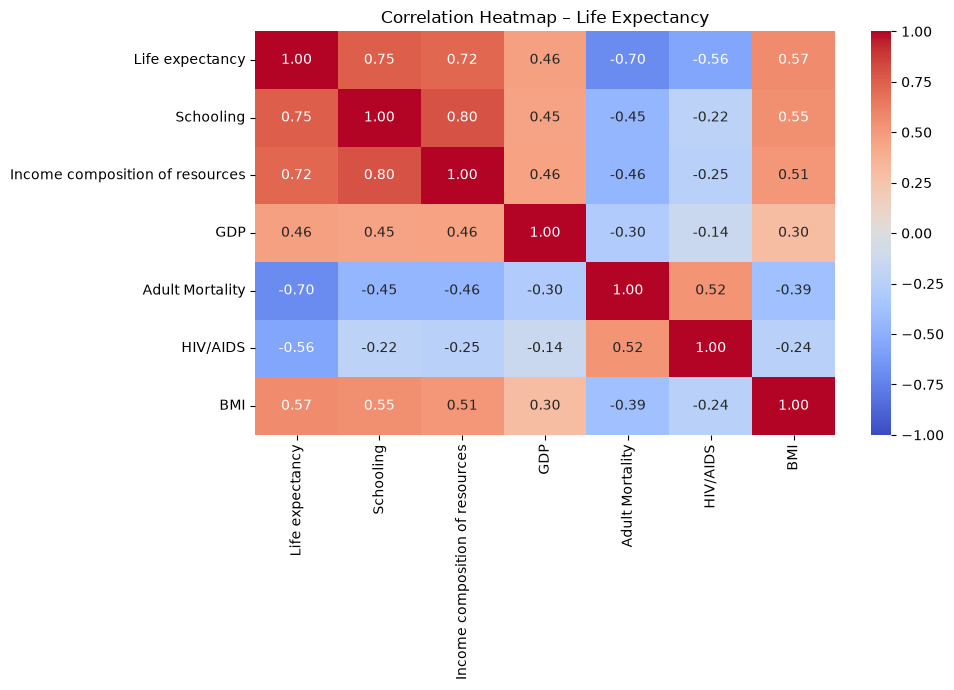

In [10]:

# Välj några viktiga variabler
columns = [
    "Life expectancy",
    "Schooling",
    "Income composition of resources",
    "GDP",
    "Adult Mortality",
    "HIV/AIDS",
    "BMI"
]

# Beräkna korrelationsmatrisen
corr_matrix = df[columns].corr()

# Skapa heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap – Life Expectancy")
plt.tight_layout()
plt.show()


### Tolkning av korrelationsmatris

Korrelationsmatrisen visar starka positiva samband mellan förväntad livslängd och utbildning (r = 0,75) samt inkomstrelaterad utveckling (r = 0,72).

Vuxendödlighet har ett starkt negativt samband med förväntad livslängd (r = −0,70).

Ett annat intressant resultat är den starka korrelationen mellan Schooling och Income composition of resources (r = 0,80). Detta kan indikera multikollinearitet, vilket behöver beaktas vid linjär regression.

Korrelationerna beskriver statistiska samband men kan inte användas som bevis för orsakssamband. Eftersom datasetet innehåller upprepade observationer av samma länder över tid behöver även skillnader mellan länder och tidsberoende beaktas.

In [11]:

from scipy.stats import pearsonr

# Välj endast rader där båda variablerna har värden
test_data = df[["Schooling", "Life expectancy"]].dropna()

# Utför Pearson-korrelationstest
r, p_value = pearsonr(
    test_data["Schooling"],
    test_data["Life expectancy"]
)

print(f"Pearson correlation: {r:.3f}")
print(f"P-value: {p_value:.6g}")
print(f"Number of observations: {len(test_data)}")

if p_value < 0.05:
    print("Statistiskt signifikant samband (p < 0.05)")
else:
    print("Inget statistiskt signifikant samband (p >= 0.05)")


Pearson correlation: 0.752
P-value: 0
Number of observations: 2768
Statistiskt signifikant samband (p < 0.05)


### Resultat av Pearson-korrelationstest

Pearson-korrelationstestet mellan utbildningsnivå (Schooling) och förväntad livslängd (Life expectancy) genomfördes med 2 768 observationer.

Resultatet visade ett starkt positivt linjärt samband (r = 0,752) med ett mycket lågt p-värde (p < 0,001).

Nollhypotesen om inget linjärt samband förkastas enligt det vanliga Pearson-testet.

Resultatet tyder på att högre utbildningsnivå är förknippad med högre förväntad livslängd. Sambandet innebär dock inte att utbildning i sig har bevisats orsaka längre livslängd.

Eftersom datasetet innehåller upprepade observationer av samma länder behöver resultaten tolkas försiktigt och kompletteras med analyser som tar hänsyn till land och år.


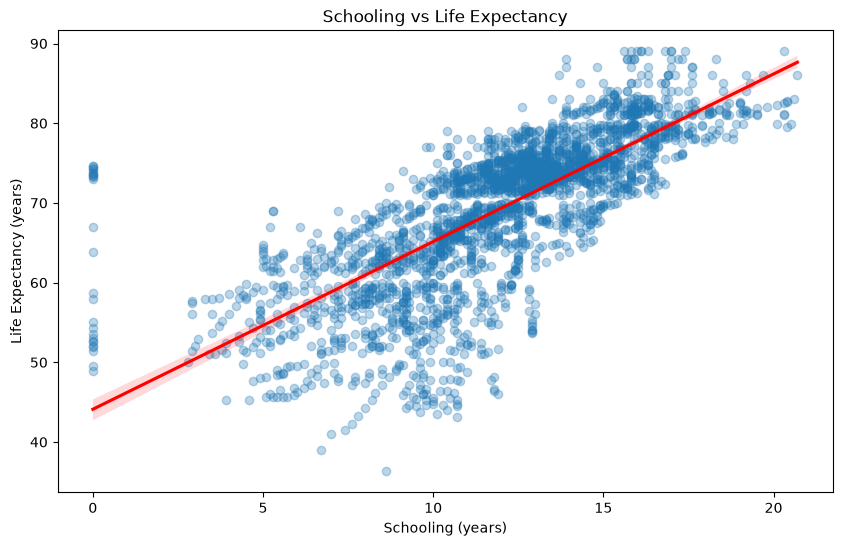

In [12]:

# Spridningsdiagram: utbildning och livslängd

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="Schooling",
    y="Life expectancy",
    scatter_kws={"alpha": 0.3},
    line_kws={"color": "red"}
)

plt.title("Schooling vs Life Expectancy")
plt.xlabel("Schooling (years)")
plt.ylabel("Life Expectancy (years)")

plt.show()


### Tolkning av scatterplot – Schooling vs Life Expectancy

Spridningsdiagrammet visar ett tydligt positivt samband mellan utbildningsnivå och förväntad livslängd.

Den uppåtgående regressionslinjen stödjer resultatet från Pearson-korrelationstestet (r = 0,752).

Samtidigt finns en betydande spridning runt regressionslinjen, vilket tyder på att utbildning inte ensam förklarar variationen i förväntad livslängd.

Diagrammet visar även observationer med Schooling = 0. Dessa värden behöver undersökas närmare för att avgöra om de representerar verkliga observationer eller datakvalitetsproblem.

Eftersom samma länder förekommer under flera år och andra faktorer kan påverka både utbildning och livslängd kan sambandet inte tolkas som ett bevis för kausalitet.

In [13]:

# Hitta observationer där Schooling är 0
zero_schooling = df[df["Schooling"] == 0]

# Visa antal observationer
print("Antal observationer med Schooling = 0:", len(zero_schooling))

# Visa vilka länder och år som berörs
zero_schooling[
    ["Country", "Year", "Schooling", "Life expectancy"]
].sort_values(["Country", "Year"])


Antal observationer med Schooling = 0: 28


,Country,Year,Schooling,Life expectancy
79,Antigua and Barbuda,2000,0.0,73.6
78,Antigua and Barbuda,2001,0.0,73.8
77,Antigua and Barbuda,2002,0.0,74.0
76,Antigua and Barbuda,2003,0.0,74.2
75,Antigua and Barbuda,2004,0.0,74.4
74,Antigua and Barbuda,2005,0.0,74.6
335,Bosnia and Herzegovina,2000,0.0,74.6
849,Equatorial Guinea,2000,0.0,52.7
1650,Marshall Islands,2013,0.0,NaN
1714,Micronesia (Federated States of),2000,0.0,67.0


In [14]:

# Välj länder där Schooling = 0
countries_with_zero = zero_schooling["Country"].unique()

# Visa utbildningsvärden för samtliga år
schooling_history = df[
    df["Country"].isin(countries_with_zero)
][["Country", "Year", "Schooling"]]

# Sortera efter land och år
schooling_history.sort_values(
    ["Country", "Year"]
)


,Country,Year,Schooling
79,Antigua and Barbuda,2000,0.0
78,Antigua and Barbuda,2001,0.0
77,Antigua and Barbuda,2002,0.0
76,Antigua and Barbuda,2003,0.0
75,Antigua and Barbuda,2004,0.0
...,...,...,...
2700,Turkmenistan,2012,10.7
2699,Turkmenistan,2013,10.7
2698,Turkmenistan,2014,10.8
2697,Turkmenistan,2015,10.8


### Datakvalitetskontroll – Schooling

Vid analys av variabeln Schooling identifierades 28 observationer med värdet 0.

Flera av dessa observationer tillhör samma länder under flera år i följd, bland annat South Sudan, Antigua and Barbuda och Montenegro.

Eftersom Schooling representerar antal utbildningsår behöver dessa värden undersökas innan datarensning genomförs.

Nästa steg är att jämföra ländernas utbildningsvärden över tid och bedöma om nollorna kan vara felkodade eller saknade uppgifter.

In [15]:

# Hitta länder som har både 0 och positiva värden
schooling_check = df.groupby("Country")["Schooling"].agg(
    has_zero=lambda x: (x == 0).any(),
    has_positive=lambda x: (x > 0).any()
)

# Välj länder där båda förekommer
countries_to_check = schooling_check[
    schooling_check["has_zero"] &
    schooling_check["has_positive"]
].index

# Visa utbildningsvärden över tid
result = df[
    df["Country"].isin(countries_to_check)
][["Country", "Year", "Schooling"]]

print("Antal länder:", len(countries_to_check))

print(
    result.sort_values(["Country", "Year"]).to_string(index=False)
)


Antal länder: 8
                         Country  Year  Schooling
             Antigua and Barbuda  2000        0.0
             Antigua and Barbuda  2001        0.0
             Antigua and Barbuda  2002        0.0
             Antigua and Barbuda  2003        0.0
             Antigua and Barbuda  2004        0.0
             Antigua and Barbuda  2005        0.0
             Antigua and Barbuda  2006       14.7
             Antigua and Barbuda  2007       14.5
             Antigua and Barbuda  2008       14.4
             Antigua and Barbuda  2009       14.2
             Antigua and Barbuda  2010       14.1
             Antigua and Barbuda  2011       14.1
             Antigua and Barbuda  2012       13.8
             Antigua and Barbuda  2013       13.9
             Antigua and Barbuda  2014       13.9
             Antigua and Barbuda  2015       13.9
          Bosnia and Herzegovina  2000        0.0
          Bosnia and Herzegovina  2001       11.6
          Bosnia and Herzegovina  

In [16]:

# Skapa en kopia av originaldatasetet
df_clean = df.copy()

# Ersätt misstänkta nollvärden med NaN
df_clean["Schooling"] = df_clean["Schooling"].replace(0, np.nan)

# Kontrollera hur många värden som saknas
print("Saknade värden före:", df["Schooling"].isnull().sum())

print("Saknade värden efter:", df_clean["Schooling"].isnull().sum())

# Kontrollera att inga nollvärden finns kvar
print("Antal nollvärden:", (df_clean["Schooling"] == 0).sum())


Saknade värden före: 163
Saknade värden efter: 191
Antal nollvärden: 0


### Data Cleaning – Schooling

Vid kontroll av utbildningsvariabeln identifierades 28 observationer med värdet 0.

En jämförelse över tid visade att vissa länder hade mycket stora förändringar mellan två år, exempelvis Antigua and Barbuda, där värdet ökade från 0 år 2005 till 14,7 år 2006.

Detta tyder på att nollvärdena kan representera saknade eller felkodade uppgifter.

Därför behandlas dessa nollvärden som saknade värden (NaN) i en separat kopia av datasetet. Originaldatan behålls oförändrad.

De saknade värdena kommer att hanteras i ett senare preprocessing-steg. För maskininlärningen ska eventuell imputering anpassas enbart på träningsdata för att undvika dataläckage.

In [17]:

# Välj variabler att undersöka
columns_to_check = [
    "GDP",
    "BMI",
    "Population",
    "Alcohol",
    "Schooling"
]

# Kontrollera lägsta, högsta värden och antal nollor
for col in columns_to_check:
    print(f"\nVariabel: {col}")
    print("Minsta värde:", df_clean[col].min())
    print("Högsta värde:", df_clean[col].max())
    print("Antal nollvärden:", (df_clean[col] == 0).sum())
    print("Antal saknade värden:", df_clean[col].isnull().sum())



Variabel: GDP
Minsta värde: 1.68135
Högsta värde: 119172.7418
Antal nollvärden: 0
Antal saknade värden: 448

Variabel: BMI
Minsta värde: 1.0
Högsta värde: 87.3
Antal nollvärden: 0
Antal saknade värden: 34

Variabel: Population
Minsta värde: 34.0
Högsta värde: 1293859294.0
Antal nollvärden: 0
Antal saknade värden: 652

Variabel: Alcohol
Minsta värde: 0.01
Högsta värde: 17.87
Antal nollvärden: 0
Antal saknade värden: 194

Variabel: Schooling
Minsta värde: 2.8
Högsta värde: 20.7
Antal nollvärden: 0
Antal saknade värden: 191


In [18]:

# Undersök de lägsta BNP-värdena
print("Lägsta GDP-värden:")
display(
    df_clean[
        ["Country", "Year", "GDP"]
    ].nsmallest(10, "GDP")
)

# Undersök de lägsta befolkningsvärdena
print("Lägsta Population-värden:")
display(
    df_clean[
        ["Country", "Year", "Population"]
    ].nsmallest(10, "Population")
)

# Undersök de högsta BMI-värdena
print("Högsta BMI-värden:")
display(
    df_clean[
        ["Country", "Year", "BMI"]
    ].nlargest(10, "BMI")
)


Lägsta GDP-värden:


,Country,Year,GDP
2036,Philippines,2002,1.681350
479,Cambodia,2000,3.685949
205,Bangladesh,2002,4.613575
2158,Rwanda,2008,5.668726
1672,Mauritius,2010,8.376432
1874,Nicaragua,2002,11.147277
2256,Senegal,2008,11.336780
2035,Philippines,2003,11.553196
2254,Senegal,2010,11.631377
896,Ethiopia,2001,12.178928


Lägsta Population-värden:


,Country,Year,Population
1614,Maldives,2003,34.0
1608,Maldives,2009,36.0
1603,Maldives,2014,41.0
985,Georgia,2008,43.0
1159,Hungary,2010,123.0
2640,Tonga,2008,135.0
2644,Tonga,2004,146.0
1617,Maldives,2000,286.0
1616,Maldives,2001,292.0
1958,Palau,2013,292.0


Högsta BMI-värden:


,Country,Year,BMI
1812,Nauru,2013,87.3
1958,Palau,2013,83.3
624,Cook Islands,2013,82.8
1650,Marshall Islands,2013,81.6
2713,Tuvalu,2013,79.3
1378,Kiribati,2015,77.6
1909,Niue,2013,77.3
1379,Kiribati,2014,77.1
1380,Kiribati,2013,76.7
1381,Kiribati,2012,76.2


In [19]:

%pip install requests


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:

import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# World Bank API - BNP per capita i Sverige
url = "https://api.worldbank.org/v2/country/SWE/indicator/NY.GDP.PCAP.CD"

params = {
    "format": "json",
    "date": "2000:2015",
    "per_page": 100
}

# Skapa en anslutning som hanterar tillfälliga serverfel
session = requests.Session()

retry_strategy = Retry(
    total=3,
    backoff_factor=1,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"]
)

adapter = HTTPAdapter(max_retries=retry_strategy)

session.mount("https://", adapter)

try:
    response = session.get(
        url,
        params=params,
        timeout=30
    )

    response.raise_for_status()

    data = response.json()

    if len(data) > 1 and data[1]:
        print("API fungerar!")

        for item in data[1][:5]:
            print(item["date"], item["value"])
    else:
        print("API svarade, men inga värden hittades.")

except requests.exceptions.RequestException as e:
    print("World Bank API är tillfälligt otillgängligt.")
    print("Fel:", e)
    print("Tidigare sparade data påverkas inte.")



API fungerar!
2015 51188.1652120493
2014 59583.4584491714
2013 60843.9888799369
2012 57749.5615420853
2011 60379.4814599322


In [21]:

# World Bank API - BNP per capita för alla länder
url = "https://api.worldbank.org/v2/country/all/indicator/NY.GDP.PCAP.CD"

params = {
    "format": "json",
    "date": "2000:2015",
    "per_page": 20000
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

data = response.json()[1]

# Skapa en DataFrame
gdp_api = pd.DataFrame([
    {
        "Country": item["country"]["value"],
        "Country_Code": item["countryiso3code"],
        "Year": int(item["date"]),
        "GDP_API": item["value"]
    }
    for item in data
    if item["value"] is not None
])

# Visa resultatet
print("Antal observationer:", len(gdp_api))
gdp_api.head()


Antal observationer: 4133


,Country,Country_Code,Year,GDP_API
0,Africa Eastern and Southern,AFE,2015,1498.715971
1,Africa Eastern and Southern,AFE,2014,1689.982381
2,Africa Eastern and Southern,AFE,2013,1705.839003
3,Africa Eastern and Southern,AFE,2012,1731.869096
4,Africa Eastern and Southern,AFE,2011,1761.838296


In [22]:

# Antal unika länder i Kaggle
print("Kaggle - antal länder:",
      df_clean["Country"].nunique())

# Antal unika namn i World Bank
print("World Bank - antal länder/regioner:",
      gdp_api["Country"].nunique())

# Hitta namn som finns i Kaggle men inte i World Bank
kaggle_countries = set(df_clean["Country"].unique())
worldbank_countries = set(gdp_api["Country"].unique())

missing_countries = sorted(
    kaggle_countries - worldbank_countries
)

print("\nAntal länder utan exakt namnmatchning:",
      len(missing_countries))

print("\nLänder som behöver kontrolleras:")
for country in missing_countries:
    print(country)


Kaggle - antal länder: 193
World Bank - antal länder/regioner: 262

Antal länder utan exakt namnmatchning: 30

Länder som behöver kontrolleras:
Bahamas
Bolivia (Plurinational State of)
Congo
Cook Islands
Côte d'Ivoire
Democratic People's Republic of Korea
Democratic Republic of the Congo
Egypt
Gambia
Iran (Islamic Republic of)
Kyrgyzstan
Lao People's Democratic Republic
Micronesia (Federated States of)
Nauru
Niue
Republic of Korea
Republic of Moldova
Saint Kitts and Nevis
Saint Lucia
Saint Vincent and the Grenadines
Slovakia
Somalia
Swaziland
The former Yugoslav republic of Macedonia
Turkey
United Kingdom of Great Britain and Northern Ireland
United Republic of Tanzania
United States of America
Venezuela (Bolivarian Republic of)
Yemen


In [23]:

%pip install pycountry


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:

import pycountry

# Länder som behöver särskild hantering
country_mapping = {
    "Bolivia (Plurinational State of)": "BOL",
    "Congo": "COG",
    "Democratic Republic of the Congo": "COD",
    "Côte d'Ivoire": "CIV",
    "Iran (Islamic Republic of)": "IRN",
    "Lao People's Democratic Republic": "LAO",
    "Micronesia (Federated States of)": "FSM",
    "Republic of Korea": "KOR",
    "Republic of Moldova": "MDA",
    "Swaziland": "SWZ",
    "The former Yugoslav republic of Macedonia": "MKD",
    "Turkey": "TUR",
    "United Republic of Tanzania": "TZA",
    "United States of America": "USA",
    "Venezuela (Bolivarian Republic of)": "VEN",
    "Viet Nam": "VNM"
}

# Funktion för att hitta landskod
def get_country_code(country):
    if country in country_mapping:
        return country_mapping[country]

    try:
        return pycountry.countries.lookup(country).alpha_3
    except LookupError:
        return None

# Skapa landskoder
df_clean["Country_Code"] = df_clean["Country"].apply(
    get_country_code
)

# Kontrollera länder utan landskod
missing_codes = df_clean[
    df_clean["Country_Code"].isna()
]["Country"].unique()

print("Länder utan landskod:", len(missing_codes))
print(missing_codes)


Länder utan landskod: 0
<ArrowStringArray>
[]
Length: 0, dtype: str


###  Standardisering av landsnamn med ISO3-koder

För att kunna kombinera Kaggle-datasetet med externa data från World Bank API behöver länderna identifieras på ett enhetligt sätt.

Vid en tidigare jämförelse upptäcktes att 30 länder saknade exakt namnmatchning mellan datakällorna. Detta beror bland annat på skillnader i hur landsnamnen skrivs.

Därför används Python-biblioteket `pycountry` för att tilldela länder standardiserade ISO3-landskoder. För vissa länder används en manuell mappning.

**Resultat:**
- 193 länder finns i Kaggle-datasetet.
- Samtliga länder har tilldelats en landskod.
- Inga länder saknar landskod efter standardiseringen.

Detta förbereder datasetet för en mer tillförlitlig sammanslagning med World Bank-data baserat på landskod och år.

### Kontroll av matchning mellan Kaggle och World Bank

Efter standardisering av landskoder undersöks hur många länder som förekommer i båda datakällorna.

Syftet är att säkerställa att data kan kombineras korrekt innan sammanslagningen genomförs.

Matchningen görs med ISO3-landskoder i stället för landsnamn för att undvika problem med olika stavningar och benämningar.

Länder utan matchning identifieras för vidare kontroll. Vi undersöker även om vissa World Bank-koder avser regionala sammanställningar i stället för enskilda länder.

In [25]:

# Hämta unika landskoder från Kaggle
kaggle_codes = set(
    df_clean["Country_Code"].dropna().unique()
)

# Hämta unika landskoder från World Bank
worldbank_codes = set(
    gdp_api["Country_Code"].dropna().unique()
)

# Kontrollera matchning
matched_codes = kaggle_codes & worldbank_codes
unmatched_codes = kaggle_codes - worldbank_codes

print("Antal länder i Kaggle:", len(kaggle_codes))
print("Antal matchade landskoder:", len(matched_codes))
print("Antal landskoder utan matchning:", len(unmatched_codes))

# Visa länder som inte matchar
unmatched_df = df_clean[
    df_clean["Country_Code"].isin(unmatched_codes)
][["Country", "Country_Code"]].drop_duplicates()

display(unmatched_df.sort_values("Country"))


Antal länder i Kaggle: 193
Antal matchade landskoder: 190
Antal landskoder utan matchning: 3


,Country,Country_Code
624,Cook Islands,COK
705,Democratic People's Republic of Korea,PRK
1909,Niue,NIU


### Resultat – Matchning mellan Kaggle och World Bank

Efter standardisering med ISO3-landskoder jämfördes länderna i Kaggle-datasetet med BNP-data från World Bank API.

**Resultat:**
- Antal länder i Kaggle: 193
- Antal matchade länder: 190
- Antal länder utan matchning: 3
- Matchningsgrad: cirka 98,4 %

De tre länderna utan matchning är Cook Islands (COK), Democratic People's Republic of Korea (PRK) och Niue (NIU).

Resultatet visar att landskoder fungerar betydligt bättre än direkt matchning på landsnamn.

Nästa steg är att kombinera datakällorna med hjälp av landskod och år samt kontrollera hur många observationer som har tillgängliga BNP-värden.

Länder utan matchning ska inte tas bort automatiskt, utan deras saknade API-värden kommer att hanteras i den fortsatta datarensningen.

###  – Sammanslagning av Kaggle och World Bank API

I detta steg kombineras det ursprungliga Life Expectancy-datasetet med BNP per capita från World Bank API.

Sammanslagningen görs med hjälp av två gemensamma variabler: ISO3-landskod (Country_Code) och år (Year).

En left join används för att behålla samtliga observationer från Kaggle, även om motsvarande BNP-värde saknas i World Bank.

De ursprungliga BNP-värdena behålls så att skillnader mellan datakällorna kan analyseras innan någon eventuell korrigering genomförs.

In [26]:

# Förbered BNP-data för sammanslagning
gdp_to_merge = gdp_api[
    ["Country_Code", "Year", "GDP_API"]
].copy()


In [27]:

# Hitta dubbletter i World Bank-data
duplicates = gdp_to_merge[
    gdp_to_merge.duplicated(
        subset=["Country_Code", "Year"],
        keep=False
    )
]

print("Antal dubblerade rader:", len(duplicates))

# Visa de första 20
display(
    duplicates.sort_values(
        ["Country_Code", "Year"]
    ).head(20)
)


Antal dubblerade rader: 64


,Country_Code,Year,GDP_API
271,,2000,22428.172607
463,,2000,317.461778
479,,2000,591.615874
751,,2000,1770.111281
270,,2001,22129.018998
462,,2001,291.602896
478,,2001,590.256242
750,,2001,1752.860196
269,,2002,22974.359265
461,,2002,312.033046


### Rensning av API-data och sammanslagning

Vid kontroll av World Bank-datan identifierades 64 rader som ingick i dubblettgrupper baserat på landskod och år.

Undersökningen visade att dessa rader hade tomma landskoder. Detta innebär att flera observationer delar samma ofullständiga identifierare och därför inte kan matchas entydigt med Kaggle-datasetet.

För att lösa problemet filtreras observationer utan giltiga landskoder bort från API-tabellen som används för sammanslagning.

Därefter genomförs en left join mellan Kaggle och World Bank med ISO3-landskod och år.

Syftet är att komplettera datasetet med BNP per capita från World Bank utan att förlora observationer från Kaggle eller skapa extra rader.

In [28]:

# Skapa en kopia av API-datan
gdp_api_clean = gdp_to_merge.copy()

# Ta bort tomma landskoder
gdp_api_clean["Country_Code"] = (
    gdp_api_clean["Country_Code"].str.strip()
)

gdp_api_clean = gdp_api_clean[
    gdp_api_clean["Country_Code"].notna() &
    (gdp_api_clean["Country_Code"] != "")
].copy()

# Kontrollera dubbletter igen
print("Dubbletter efter rensning:",
      gdp_api_clean.duplicated(
          ["Country_Code", "Year"]
      ).sum())

# Slå ihop Kaggle och World Bank
df_merged = df_clean.merge(
    gdp_api_clean,
    on=["Country_Code", "Year"],
    how="left",
    validate="many_to_one"
)

# Kontrollera resultatet
print("Rader före:", len(df_clean))
print("Rader efter:", len(df_merged))

print("Med BNP från API:",
      df_merged["GDP_API"].notna().sum())

print("Utan BNP från API:",
      df_merged["GDP_API"].isna().sum())

# Visa resultatet
display(
    df_merged[
        ["Country", "Year", "GDP", "GDP_API"]
    ].head(10)
)


Dubbletter efter rensning: 0
Rader före: 2938
Rader efter: 2938
Med BNP från API: 2908
Utan BNP från API: 30


,Country,Year,GDP,GDP_API
0,Afghanistan,2015,584.259210,565.569730
1,Afghanistan,2014,612.696514,625.054942
2,Afghanistan,2013,631.744976,637.087099
3,Afghanistan,2012,669.959000,651.417134
4,Afghanistan,2011,63.537231,606.694676
5,Afghanistan,2010,553.328940,560.621505
6,Afghanistan,2009,445.893298,452.053705
7,Afghanistan,2008,373.361116,381.733238
8,Afghanistan,2007,369.835796,376.223152
9,Afghanistan,2006,272.563770,274.218554


### Resultat – Sammanslagning med World Bank API

Sammanslagningen mellan Kaggle-datasetet och World Bank API genomfördes med hjälp av ISO3-landskoder och år.

**Resultat:**
- Antal observationer före sammanslagning: 2 938
- Antal observationer efter sammanslagning: 2 938
- Antal dubbletter i den rensade API-tabellen: 0
- Observationer med BNP-data från World Bank: 2 908
- Observationer utan BNP-data från World Bank: 30
- Täckningsgrad: cirka 99 %

Samtliga observationer från Kaggle behölls tack vare en left join. Detta innebär att inga rader förlorades vid sammanslagningen.

En första jämförelse visar att BNP-värdena från Kaggle och World Bank inte alltid är identiska. Skillnaderna behöver undersökas innan beslut fattas om vilken datakälla som ska användas för maskininlärningen.

### Jämförelse och validering av BNP-data

I detta steg jämförs BNP per capita från Kaggle med motsvarande värden från World Bank API.

Syftet är att identifiera avvikelser mellan datakällorna och bedöma vilka värden som är mest tillförlitliga.

För varje observation beräknas den procentuella skillnaden mellan Kaggle och World Bank. Vi undersöker därefter de observationer som har störst avvikelser.

Denna kontroll används som underlag för beslut om eventuell korrigering av BNP-variabeln inför maskininlärningen.

In [29]:

# Välj observationer där båda BNP-värdena finns
gdp_comparison = df_merged[
    df_merged["GDP"].notna() &
    df_merged["GDP_API"].notna() &
    (df_merged["GDP_API"] > 0)
].copy()

# Beräkna procentuell skillnad
gdp_comparison["GDP_Diff_Percent"] = (
    (gdp_comparison["GDP"] - gdp_comparison["GDP_API"])
    / gdp_comparison["GDP_API"] * 100
)

# Beräkna absolut procentuell skillnad
gdp_comparison["Abs_Diff_Percent"] = (
    gdp_comparison["GDP_Diff_Percent"].abs()
)

# Visa sammanfattning
print("Antal jämförbara observationer:",
      len(gdp_comparison))

print("Median absolut skillnad (%):",
      round(gdp_comparison["Abs_Diff_Percent"].median(), 2))

print("Observationer med över 20 % skillnad:",
      (gdp_comparison["Abs_Diff_Percent"] > 20).sum())

# Visa de 10 största avvikelserna
display(
    gdp_comparison[
        ["Country", "Year", "GDP",
         "GDP_API", "GDP_Diff_Percent"]
    ].loc[
        gdp_comparison["Abs_Diff_Percent"].nlargest(10).index
    ]
)


Antal jämförbara observationer: 2490
Median absolut skillnad (%): 8.02
Observationer med över 20 % skillnad: 960


,Country,Year,GDP,GDP_API,GDP_Diff_Percent
1174,Iceland,2011,46.217000,48254.953927,-99.904223
1672,Mauritius,2010,8.376432,8113.176707,-99.896755
1296,Italy,2001,24.819000,20570.438592,-99.879346
2120,Romania,2014,12.277330,10031.771076,-99.877616
2036,Philippines,2002,1.681350,1014.908793,-99.834335
1107,Guyana,2014,43.823210,5472.688205,-99.199238
2256,Senegal,2008,11.336780,1398.792180,-99.189531
2827,Uzbekistan,2014,25.448414,3021.003317,-99.157617
2266,Serbia,2014,62.173221,6886.678091,-99.097196
2254,Senegal,2010,11.631377,1275.883575,-99.088367


### Resultat – Jämförelse av BNP-data

För att kontrollera datakvaliteten jämfördes BNP per capita från Kaggle med motsvarande uppgifter från World Bank API.

Totalt kunde 2 490 observationer jämföras.

**Resultat:**
- Medianen för den absoluta procentuella skillnaden var 8,02 %.
- 960 observationer hade en skillnad större än 20 %.
- Detta motsvarar cirka 38,6 % av de jämförbara observationerna.

De största avvikelserna identifierades bland annat i Island, Mauritius, Italien och Filippinerna. I vissa fall var Kaggle-värdena mer än 99 % lägre än motsvarande värden från World Bank.

Resultaten tyder på betydande datakvalitetsproblem eller skillnader i datadefinitioner.

Innan maskininlärningen genomförs behöver en konsekvent BNP-källa väljas. World Bank API är en lämplig kandidat eftersom det erbjuder dokumenterade och uppdaterade makroekonomiska indikatorer.

### Standardisering av BNP-variabeln

Analysen visade betydande skillnader mellan BNP-värden från Kaggle och World Bank API.

För att skapa en mer konsekvent datakälla används World Banks BNP per capita i löpande USD som primär variabel.

En ny kolumn, GDP_Final, skapas utifrån GDP_API. De ursprungliga kolumnerna behålls för jämförelse och spårbarhet.

Observationer där World Bank saknar BNP-värden lämnas tills vidare som NaN. Dessa hanteras senare i preprocessing, där metoderna anpassas efter träningsdata för att minska risken för dataläckage.

In [30]:

# Skapa en kopia av sammanslagen data
df_final = df_merged.copy()

# Använd BNP per capita från World Bank
df_final["GDP_Final"] = df_final["GDP_API"]

# Kontrollera resultatet
print("Antal observationer:", len(df_final))

print("GDP_Final - tillgängliga värden:",
      df_final["GDP_Final"].notna().sum())

print("GDP_Final - saknade värden:",
      df_final["GDP_Final"].isna().sum())

# Visa ursprunglig och ny BNP bredvid varandra
display(
    df_final[
        ["Country", "Year", "GDP", "GDP_API", "GDP_Final"]
    ].head(10)
)


Antal observationer: 2938
GDP_Final - tillgängliga värden: 2908
GDP_Final - saknade värden: 30


,Country,Year,GDP,GDP_API,GDP_Final
0,Afghanistan,2015,584.259210,565.569730,565.569730
1,Afghanistan,2014,612.696514,625.054942,625.054942
2,Afghanistan,2013,631.744976,637.087099,637.087099
3,Afghanistan,2012,669.959000,651.417134,651.417134
4,Afghanistan,2011,63.537231,606.694676,606.694676
5,Afghanistan,2010,553.328940,560.621505,560.621505
6,Afghanistan,2009,445.893298,452.053705,452.053705
7,Afghanistan,2008,373.361116,381.733238,381.733238
8,Afghanistan,2007,369.835796,376.223152,376.223152
9,Afghanistan,2006,272.563770,274.218554,274.218554


### Databerikning med befolkningsstatistik från World Bank API

Vid tidigare datakvalitetskontroller identifierades misstänkta befolkningsvärden i Kaggle-datasetet. Exempelvis registrerades Maldivernas befolkning som 34 personer år 2003, vilket inte är rimligt för ett helt land.

För att förbättra datakvaliteten hämtas officiell befolkningsstatistik från World Bank API med indikatorn SP.POP.TOTL (Total Population).

Data hämtas för perioden 2000–2015 och ska kopplas till det befintliga datasetet med hjälp av ISO3-landskod och år.

Syftet är att skapa en mer tillförlitlig befolkningsvariabel inför den fortsatta statistiska analysen och maskininlärningen. De ursprungliga värdena behålls för jämförelse och spårbarhet.

In [31]:

# World Bank API - Befolkning för alla länder
url = "https://api.worldbank.org/v2/country/all/indicator/SP.POP.TOTL"

params = {
    "format": "json",
    "date": "2000:2015",
    "per_page": 20000
}

# Hämta befolkningsdata
response = requests.get(url, params=params, timeout=60)
response.raise_for_status()

data = response.json()[1]

# Skapa en DataFrame
population_api = pd.DataFrame([
    {
        "Country_Code": item["countryiso3code"],
        "Year": int(item["date"]),
        "Population_API": item["value"]
    }
    for item in data
    if item["value"] is not None
])

# Ta bort tomma landskoder
population_api["Country_Code"] = (
    population_api["Country_Code"].str.strip()
)

population_api = population_api[
    population_api["Country_Code"].notna() &
    (population_api["Country_Code"] != "")
].copy()

# Kontrollera antal observationer och dubbletter
print("Antal observationer:", len(population_api))

print("Antal dubbletter:",
      population_api.duplicated(
          ["Country_Code", "Year"]
      ).sum())

# Visa de första raderna
display(population_api.head())


HTTPError: 502 Server Error: Bad Gateway for url: https://api.worldbank.org/v2/country/all/indicator/SP.POP.TOTL?format=json&date=2000%3A2015&per_page=20000

### Resultat – Hämtning av befolkningsdata

Befolkningsstatistik för perioden 2000–2015 hämtades från World Bank API med indikatorn SP.POP.TOTL.

Efter filtrering av observationer med tomma landskoder återstod 4 176 observationer. Kontrollen visade inga dubbletter baserat på kombinationen landskod och år.

API-datan innehåller både enskilda länder och regionala sammanställningar. Vid sammanslagningen kommer endast de landskoder som matchar Kaggle-datasetet att användas.

Nästa steg är att kombinera befolkningsuppgifterna med det befintliga datasetet och kontrollera datatäckningen.

### Sammanslagning av befolkningsdata

Befolkningsdata från World Bank kombineras med det befintliga datasetet med hjälp av ISO3-landskod och år.

En left join används för att behålla alla ursprungliga observationer. Befolkningsvärden från API sparas i en separat kolumn, Population_API.

Därefter skapas Population_Final, som innehåller World Banks befolkningsuppgifter. De ursprungliga värdena från Kaggle behålls för jämförelse och spårbarhet.

Efter sammanslagningen kontrolleras antal rader, tillgängliga värden och eventuella saknade uppgifter.

In [ ]:

# Steg 28 - Slå ihop befolkningsdata

# Behåll endast landskoder från Kaggle
population_to_merge = population_api[
    population_api["Country_Code"].isin(
        df_final["Country_Code"]
    )
].copy()

# Kontrollera att land + år är unikt
print("Dubbletter:",
      population_to_merge.duplicated(
          ["Country_Code", "Year"]
      ).sum())

# Slå ihop med befintligt dataset
df_final = df_final.merge(
    population_to_merge,
    on=["Country_Code", "Year"],
    how="left",
    validate="many_to_one"
)

# Skapa vår slutliga befolkningsvariabel
df_final["Population_Final"] = df_final["Population_API"]

# Kontrollera resultat
print("Antal rader:", len(df_final))

print("Med befolkningsdata:",
      df_final["Population_Final"].notna().sum())

print("Utan befolkningsdata:",
      df_final["Population_Final"].isna().sum())

# Jämför original och API
display(
    df_final[
        ["Country", "Year",
         "Population", "Population_API", "Population_Final"]
    ].head(10)
)


Dubbletter: 0
Antal rader: 2938
Med befolkningsdata: 2936
Utan befolkningsdata: 2


,Country,Year,Population,Population_API,Population_Final
0,Afghanistan,2015,33736494.0,33831764.0,33831764.0
1,Afghanistan,2014,327582.0,32792523.0,32792523.0
2,Afghanistan,2013,31731688.0,31622704.0,31622704.0
3,Afghanistan,2012,3696958.0,30560034.0,30560034.0
4,Afghanistan,2011,2978599.0,29347708.0,29347708.0
5,Afghanistan,2010,2883167.0,28284089.0,28284089.0
6,Afghanistan,2009,284331.0,27466101.0,27466101.0
7,Afghanistan,2008,2729431.0,26482622.0,26482622.0
8,Afghanistan,2007,26616792.0,25909852.0,25909852.0
9,Afghanistan,2006,2589345.0,25424094.0,25424094.0


### Resultat – Sammanslagning av befolkningsdata

Befolkningsstatistik från World Bank API har framgångsrikt integrerats med Life Expectancy-datasetet.

**Resultat:**
- Antal observationer: 2 938
- Antal dubbletter i API-tabellen: 0
- Observationer med befolkningsdata: 2 936
- Observationer utan befolkningsdata: 2
- Datatäckning: cirka 99,93 %

Samtliga observationer från Kaggle behölls efter sammanslagningen.

En första jämförelse visar stora skillnader mellan vissa befolkningsvärden i Kaggle och World Bank. Exempelvis anges Afghanistans befolkning år 2014 till 327 582 i Kaggle, medan World Bank anger 32 792 523.

Detta tyder på datakvalitetsproblem i den ursprungliga befolkningsvariabeln.

Därför används World Banks uppgifter som primär befolkningskälla i Population_Final. Originalvärdena behålls för jämförelse och spårbarhet.

### Kontroll av saknade befolkningsuppgifter

Efter sammanslagningen identifierades två observationer som saknar befolkningsuppgifter från World Bank API.

Syftet med denna kontroll är att identifiera vilka länder och år som berörs samt undersöka om motsvarande värden finns i Kaggle-datasetet.

Dessa observationer granskas innan beslut fattas om eventuell komplettering eller hantering av saknade värden inför maskininlärningen.

In [ ]:

# Hitta observationer utan befolkningsdata från API
missing_population = df_final[
    df_final["Population_Final"].isna()
]

# Visa land, år och tidigare befolkningsvärde
display(
    missing_population[
        ["Country", "Country_Code", "Year",
         "Population", "Population_Final"]
    ]
)


,Country,Country_Code,Year,Population,Population_Final
624,Cook Islands,COK,2013,NaN,NaN
1909,Niue,NIU,2013,NaN,NaN


### Resultat – Saknade befolkningsuppgifter

Efter kontroll av den sammanslagna datan identifierades två observationer som saknar befolkningsuppgifter:

- Cook Islands (2013)
- Niue (2013)

Befolkningsuppgifter saknas både i det ursprungliga Kaggle-datasetet och i de hämtade World Bank-uppgifterna.

Totalt finns befolkningsdata för 2 936 av 2 938 observationer, vilket motsvarar cirka 99,93 %.

De två observationerna behålls tills vidare och värdena lämnas som NaN. Eventuell imputering hanteras senare i preprocessing för maskininlärningen.

###  Sammanfattande datakvalitetskontroll

Efter integrationen med World Bank API genomförs en sammanfattande kontroll av det berikade datasetet.

Syftet är att säkerställa att sammanslagningarna inte har skapat extra observationer, att de nya BNP- och befolkningsvariablerna innehåller korrekta datatyper och att saknade värden är dokumenterade.

Originalvariablerna från Kaggle behålls för spårbarhet. De externa variablerna GDP_Final och Population_Final används som primära källor i den fortsatta analysen.

Denna kontroll utgör ett underlag för nästa steg: preprocessing och maskininlärning.

In [ ]:

# Kontrollera storleken på slutligt dataset
print("Antal rader och kolumner:", df_final.shape)

# Kontrollera dubbletter per land och år
print("Dubbletter per land och år:",
      df_final.duplicated(
          ["Country_Code", "Year"]
      ).sum())

# Kontrollera viktiga variabler
columns = [
    "Life expectancy",
    "Schooling",
    "GDP_Final",
    "Population_Final"
]

summary = pd.DataFrame({
    "Datatyp": df_final[columns].dtypes.astype(str),
    "Saknade värden": df_final[columns].isna().sum(),
    "Andel saknade (%)": (
        df_final[columns].isna().mean() * 100
    ).round(2)
})

display(summary)


Antal rader och kolumner: (2938, 27)
Dubbletter per land och år: 0


,Datatyp,Saknade värden,Andel saknade (%)
Life expectancy,float64,10,0.34
Schooling,float64,191,6.50
GDP_Final,float64,30,1.02
Population_Final,float64,2,0.07


### Resultat – Sammanfattande datakvalitetskontroll

Efter integrationen med World Bank API innehåller datasetet 2 938 observationer och 27 kolumner.

Kontrollen visade inga dubbletter baserat på landskod och år. Samtliga ursprungliga observationer har därmed behållits.

De viktigaste variablerna har följande andel saknade värden:

- Life expectancy: 0,34 %
- Schooling: 6,50 %
- GDP_Final: 1,02 %
- Population_Final: 0,07 %

Genom API-integrationen har BNP- och befolkningsuppgifter kompletterats med data från World Bank. De ursprungliga variablerna har behållits för spårbarhet.

Resultatet visar att datasetet har god täckning för de utvalda variablerna. Ytterligare preprocessing krävs dock innan maskininlärningsmodellerna kan tränas.

### Val av målvariabel och förklarande variabler

Syftet med maskininlärningen är att uppskatta förväntad livslängd utifrån socioekonomiska indikatorer.

Målvariabeln är Life expectancy, som mäts i antal år.

För den första modellen väljs Schooling, Income composition of resources, GDP_Final och Population_Final som förklarande variabler.

De ursprungliga BNP- och befolkningsvariablerna ersätts med motsvarande World Bank-data.

Observationer där målvariabeln saknas exkluderas, eftersom modellen behöver ett känt utfall under träningen.

Saknade värden i de förklarande variablerna lämnas tills vidare oförändrade och kommer att hanteras inom modellens preprocessing för att undvika dataläckage.

In [ ]:

# Skapa en separat DataFrame för maskininlärning
ml_columns = [
    "Country",
    "Year",
    "Life expectancy",
    "Schooling",
    "Income composition of resources",
    "GDP_Final",
    "Population_Final"
]

df_ml = df_final[ml_columns].copy()

# Ta bort endast rader där målvariabeln saknas
df_ml = df_ml.dropna(subset=["Life expectancy"])

# Visa resultat
print("Antal observationer för ML:", len(df_ml))
print("Antal kolumner:", df_ml.shape[1])

# Kontrollera saknade värden
display(df_ml.isnull().sum())

# Visa de första fem raderna
display(df_ml.head())


Antal observationer för ML: 2928
Antal kolumner: 7


Country                              0
Year                                 0
Life expectancy                      0
Schooling                          186
Income composition of resources    160
GDP_Final                           28
Population_Final                     0
dtype: int64

,Country,Year,Life expectancy,Schooling,Income composition of resources,GDP_Final,Population_Final
0,Afghanistan,2015,65.0,10.1,0.479,565.569730,33831764.0
1,Afghanistan,2014,59.9,10.0,0.476,625.054942,32792523.0
2,Afghanistan,2013,59.9,9.9,0.470,637.087099,31622704.0
3,Afghanistan,2012,59.5,9.8,0.463,651.417134,30560034.0
4,Afghanistan,2011,59.2,9.5,0.454,606.694676,29347708.0


### Resultat – Förberedelse av dataset för maskininlärning

Efter att observationer med saknad målvariabel (Life expectancy) exkluderats återstår 2 928 observationer och 7 kolumner.

Målvariabeln innehåller nu inga saknade värden.

Vissa förklarande variabler har fortfarande saknade uppgifter:
- Schooling: 186
- Income composition of resources: 160
- GDP_Final: 28
- Population_Final: 0

Dessa värden kommer att hanteras med imputering, där medianvärden beräknas på träningsdatan och sedan tillämpas på testdatan.

Detta minskar risken för dataläckage och gör modellutvärderingen mer tillförlitlig.

### Tidsbaserad uppdelning i tränings- och testdata

För att utvärdera maskininlärningsmodellernas förmåga att generalisera till senare tidsperioder delas datasetet upp efter år.

Observationer från 2000–2012 används som träningsdata, medan observationer från 2013–2015 används som testdata.

En tidsbaserad uppdelning väljs framför en slumpmässig uppdelning eftersom datasetet innehåller upprepade observationer av samma länder under flera år.

Uppdelningen säkerställer att modellen inte tränas på observationer från testperioden. Samma länder kan dock förekomma i båda grupperna.

Imputering och annan preprocessing kommer att anpassas endast efter träningsdatan för att undvika dataläckage.

In [ ]:

# Steg 32 - Tidsbaserad uppdelning

# Träningsdata: 2000–2012
train_df = df_ml[df_ml["Year"] <= 2012].copy()

# Testdata: 2013–2015
test_df = df_ml[df_ml["Year"] >= 2013].copy()

# Välj förklarande variabler
features = [
    "Schooling",
    "Income composition of resources",
    "GDP_Final",
    "Population_Final"
]

# Skapa X och y för träning
X_train = train_df[features]
y_train = train_df["Life expectancy"]

# Skapa X och y för test
X_test = test_df[features]
y_test = test_df["Life expectancy"]

# Kontrollera storleken
print("Träningsdata:", X_train.shape)
print("Testdata:", X_test.shape)

print("Träningsperiod:",
      train_df["Year"].min(),
      "-",
      train_df["Year"].max())

print("Testperiod:",
      test_df["Year"].min(),
      "-",
      test_df["Year"].max())


Träningsdata: (2379, 4)
Testdata: (549, 4)
Träningsperiod: 2000 - 2012
Testperiod: 2013 - 2015


### Resultat – Uppdelning av tränings- och testdata

Datasetet delades upp i två tidsperioder:

- Träningsdata (2000–2012): 2 379 observationer, cirka 81,3 %.
- Testdata (2013–2015): 549 observationer, cirka 18,7 %.

Fyra förklarande variabler används: Schooling, Income composition of resources, GDP_Final och Population_Final.

Den tidsbaserade uppdelningen innebär att modellen tränas på äldre observationer och utvärderas på senare år.

Syftet är att undersöka hur väl modellen kan uppskatta förväntad livslängd för år som inte ingick i träningen.

Eftersom variabler från samma år som målvariabeln används är detta en prediktionsmodell, inte en ren framtidsprognos.

### Linjär regression med preprocessing

Den första maskininlärningsmodellen är Linear Regression, en övervakad regressionsmodell som försöker uppskatta förväntad livslängd utifrån de valda förklarande variablerna.

Modellen använder fyra variabler: Schooling, Income composition of resources, GDP_Final och Population_Final.

Eftersom vissa variabler innehåller saknade värden används SimpleImputer med medianen för att ersätta dessa.

Preprocessing och modellträning kombineras i en Pipeline. Medianvärdena beräknas endast från träningsdatan och används därefter på testdatan, vilket minskar risken för dataläckage.

Resultatet ska senare jämföras med andra modeller och en enkel referensmodell.

In [ ]:

# Importera verktyg för maskininlärning
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

# Skapa vår första ML-modell
linear_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

# Träna modellen på träningsdatan
linear_model.fit(X_train, y_train)

# Gör prediktioner på testdatan
y_pred_linear = linear_model.predict(X_test)

# Visa de första fem prediktionerna
results_linear = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred_linear
})

display(results_linear.head())


,Actual,Predicted
0,65.0,63.447064
1,59.9,63.271981
2,59.9,63.061276
3,77.8,72.608028
4,77.5,72.669822


### Resultat – Första prediktionerna med Linear Regression

Den linjära regressionsmodellen tränades på observationer från perioden 2000–2012 och användes därefter för att förutsäga livslängden under testperioden 2013–2015.

Modellen har framgångsrikt genererat prediktioner baserat på utbildning, inkomstrelaterad utveckling, BNP per capita och befolkning.

En första jämförelse mellan verkliga och predikterade värden visar att modellen både över- och underskattar livslängden för olika observationer.

För att avgöra hur väl modellen fungerar behöver prediktionerna utvärderas med statistiska felmått såsom MAE, RMSE och R².

### Modellutvärdering med MAE, RMSE och R²

För att utvärdera Linear Regression används tre mått: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) och R².

MAE visar hur många år modellen i genomsnitt avviker från den verkliga livslängden.

RMSE mäter också prediktionsfel men ger större vikt åt stora avvikelser.

R² visar hur väl modellen förklarar variationen i livslängd jämfört med en konstant medelvärdesprediktion.

Modellen utvärderas på testperioden 2013–2015, som inte användes vid träningen. Resultatet kommer senare att jämföras med andra regressionsmodeller.

In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Beräkna MAE
mae_linear = mean_absolute_error(y_test, y_pred_linear)

# Beräkna RMSE
rmse_linear = np.sqrt(
    mean_squared_error(y_test, y_pred_linear)
)

# Beräkna R²
r2_linear = r2_score(y_test, y_pred_linear)

# Skriv ut resultat
print("Linear Regression - Model Evaluation")
print(f"MAE: {mae_linear:.2f} years")
print(f"RMSE: {rmse_linear:.2f} years")
print(f"R²: {r2_linear:.3f}")


Linear Regression - Model Evaluation
MAE: 3.78 years
RMSE: 4.83 years
R²: 0.665


### Resultat – Utvärdering av Linear Regression

Den linjära regressionsmodellen utvärderades på testdata från perioden 2013–2015, totalt 549 observationer.

**Resultat:**
- MAE: 3,78 år
- RMSE: 4,83 år
- R²: 0,665

MAE visar att modellens prediktioner i genomsnitt avviker med 3,78 år från den verkliga förväntade livslängden.

RMSE är högre än MAE, vilket visar att större prediktionsfel påverkar resultatet.

R²-värdet på 0,665 innebär att modellen förklarar cirka 66,5 % av variationen i testdatan jämfört med en konstant prediktion baserad på testdatans medelvärde.

Resultatet ger en första bild av modellens prediktionsförmåga. För att bedöma hur bra modellen faktiskt är behöver den jämföras med en referensmodell och andra regressionsalgoritmer.

### Referensmodell (Baseline Model)

För att bedöma om Linear Regression ger bättre prediktioner än en enkel metod skapas en referensmodell med DummyRegressor.

Referensmodellen använder träningsdatans genomsnittliga förväntade livslängd som en konstant prediktion för samtliga testobservationer.

Modellen utvärderas med samma mått som Linear Regression: MAE, RMSE och R².

Genom att jämföra dessa resultat kan vi bedöma om den linjära regressionsmodellen tillför prediktionsvärde utöver en enkel konstant uppskattning.

In [ ]:

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Skapa en enkel referensmodell
baseline_model = DummyRegressor(strategy="mean")

# Träna på träningsdatan
baseline_model.fit(X_train, y_train)

# Gör prediktioner på testdatan
y_pred_baseline = baseline_model.predict(X_test)

# Beräkna utvärderingsmått
mae_baseline = mean_absolute_error(
    y_test, y_pred_baseline
)

rmse_baseline = np.sqrt(
    mean_squared_error(y_test, y_pred_baseline)
)

r2_baseline = r2_score(
    y_test, y_pred_baseline
)

# Visa resultatet
print("Baseline Model - Evaluation")
print(f"MAE: {mae_baseline:.2f} years")
print(f"RMSE: {rmse_baseline:.2f} years")
print(f"R²: {r2_baseline:.3f}")


Baseline Model - Evaluation
MAE: 7.48 years
RMSE: 8.79 years
R²: -0.109


### Resultat – Jämförelse mellan Baseline och Linear Regression

Referensmodellen (DummyRegressor) jämfördes med den linjära regressionsmodellen på testperioden 2013–2015.

**Baseline Model:**
- MAE: 7,48 år
- RMSE: 8,79 år
- R²: −0,109

**Linear Regression:**
- MAE: 3,78 år
- RMSE: 4,83 år
- R²: 0,665

Linear Regression presterade betydligt bättre än referensmodellen. Det genomsnittliga absoluta prediktionsfelet minskade med cirka 49,5 %.

Baseline-modellens negativa R² visar att dess konstanta prediktion fungerar sämre än testdatans medelvärde som referens.

Resultatet tyder på att de utvalda förklarande variablerna innehåller relevant information för att uppskatta förväntad livslängd.

Nästa steg är att undersöka om mer avancerade maskininlärningsmodeller kan förbättra resultaten ytterligare.

### Random Forest Regression

För att undersöka om en mer flexibel modell kan förbättra prediktionsförmågan används Random Forest Regressor.

Random Forest kombinerar flera beslutsträd för att skapa en gemensam prediktion och kan fånga icke-linjära samband mellan förklarande variabler och förväntad livslängd.

Samma tränings- och testperioder samt förklarande variabler används som i Linear Regression för att möjliggöra en rättvis jämförelse.

Saknade värden hanteras med SimpleImputer i en Pipeline. Modellen utvärderas med MAE, RMSE och R².

Detta är en första modell med förvalda parametrar. Eventuell optimering av modellens parametrar kommer senare att genomföras med en separat valideringsperiod inom träningsdatan.

In [ ]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Skapa Random Forest-modellen
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Träna modellen
rf_model.fit(X_train, y_train)

# Gör prediktioner på testdatan
y_pred_rf = rf_model.predict(X_test)

# Beräkna utvärderingsmått
mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf = r2_score(y_test, y_pred_rf)

# Visa resultatet
print("Random Forest - Model Evaluation")
print(f"MAE: {mae_rf:.2f} years")
print(f"RMSE: {rmse_rf:.2f} years")
print(f"R²: {r2_rf:.3f}")


Random Forest - Model Evaluation
MAE: 2.51 years
RMSE: 3.62 years
R²: 0.812


### Resultat – Random Forest Regression

Random Forest Regressor tränades på samma träningsdata och med samma fyra förklarande variabler som Linear Regression.

**Resultat på testdata (2013–2015):**
- MAE: 2,51 år
- RMSE: 3,62 år
- R²: 0,812

Random Forest presterade bättre än både Linear Regression och referensmodellen.

Jämfört med Linear Regression minskade MAE från 3,78 till 2,51 år, vilket motsvarar en förbättring på cirka 33,6 %.

Detta tyder på att Random Forest kan fånga samband mellan variablerna som den linjära modellen inte beskriver lika väl.

Random Forest är hittills den bäst presterande modellen. Ytterligare jämförelser och validering behövs innan den slutliga modellen väljs.

### Gradient Boosting Regression

Den tredje maskininlärningsmodellen är Gradient Boosting Regressor.

Gradient Boosting bygger beslutsträd stegvis där varje nytt träd försöker minska felen från tidigare prediktioner.

Syftet är att undersöka om denna metod kan ge bättre prediktionsförmåga än Linear Regression och Random Forest.

Samma förklarande variabler och tidsbaserade tränings- och testperioder används för jämförelsen.

Saknade värden hanteras med SimpleImputer i en Pipeline. Modellen utvärderas med MAE, RMSE och R².

Modellens parametrar används inledningsvis utan hyperparameteroptimering.

In [ ]:

from sklearn.ensemble import GradientBoostingRegressor

# Skapa Gradient Boosting-modellen
gb_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

# Träna modellen
gb_model.fit(X_train, y_train)

# Gör prediktioner
y_pred_gb = gb_model.predict(X_test)

# Beräkna utvärderingsmått
mae_gb = mean_absolute_error(y_test, y_pred_gb)

rmse_gb = np.sqrt(
    mean_squared_error(y_test, y_pred_gb)
)

r2_gb = r2_score(y_test, y_pred_gb)

# Visa resultat
print("Gradient Boosting - Model Evaluation")
print(f"MAE: {mae_gb:.2f} years")
print(f"RMSE: {rmse_gb:.2f} years")
print(f"R²: {r2_gb:.3f}")


Gradient Boosting - Model Evaluation
MAE: 2.81 years
RMSE: 3.77 years
R²: 0.796


### Resultat – Gradient Boosting och modelljämförelse

Gradient Boosting Regressor tränades på samma träningsdata som de tidigare modellerna och utvärderades på testperioden 2013–2015.

**Gradient Boosting – resultat:**
- MAE: 2,81 år
- RMSE: 3,77 år
- R²: 0,796

Gradient Boosting presterade bättre än Linear Regression men något sämre än Random Forest.

Vid jämförelse av samtliga fyra modeller uppnådde Random Forest det bästa resultatet med MAE 2,51 år, RMSE 3,62 år och R² 0,812.

Detta indikerar att Random Forest kan hantera sambanden mellan de valda socioekonomiska variablerna och förväntad livslängd på ett effektivt sätt.

Resultatet är preliminärt eftersom modellerna hittills har jämförts på en gemensam testperiod. För ett mer tillförlitligt modellval behövs ytterligare validering och analys av prediktionsfelen.

### Feature Importance för Random Forest

För att bättre förstå Random Forest-modellen analyseras hur mycket de olika förklarande variablerna bidrar till modellens beslut.

Feature Importance visar den relativa betydelsen av varje variabel enligt Random Forest-modellens interna beräkning.

Syftet är att identifiera vilka indikatorer som modellen främst använder för att uppskatta förväntad livslängd.

Resultaten ska tolkas försiktigt eftersom variabler kan vara korrelerade med varandra. Hög Feature Importance innebär inte automatiskt att en variabel orsakar förändringar i livslängden.

,Feature,Importance
1,Income composition of resources,0.606319
2,GDP_Final,0.208723
3,Population_Final,0.130620
0,Schooling,0.054339


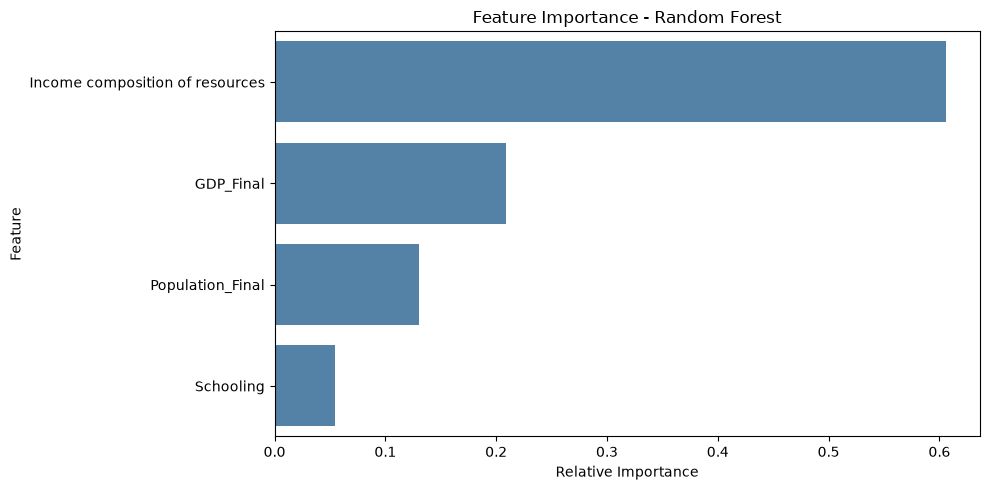

In [ ]:

# Hämta den tränade Random Forest-modellen
rf = rf_model.named_steps["model"]

# Hämta variablernas betydelse
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
})

# Sortera från högsta till lägsta betydelse
importance = importance.sort_values(
    "Importance",
    ascending=False
)

# Visa tabellen
display(importance)

# Skapa diagram
plt.figure(figsize=(10, 5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Feature Importance - Random Forest")
plt.xlabel("Relative Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


### Resultat – Feature Importance för Random Forest

Analysen av Feature Importance visar att Income composition of resources är den viktigaste variabeln i Random Forest-modellen, med en relativ betydelse på 60,63 %.

Därefter följer GDP_Final (20,87 %), Population_Final (13,06 %) och Schooling (5,43 %).

Ett intressant resultat är att Schooling tidigare hade en stark positiv korrelation med förväntad livslängd (r = 0,752), men får relativt låg betydelse i modellen.

En möjlig förklaring är den starka korrelationen mellan Schooling och Income composition of resources (r = 0,80), vilket innebär att variablerna delvis kan innehålla överlappande information.

Feature Importance beskriver hur modellen använder variablerna, men visar inte orsakssamband. Resultaten behöver därför kompletteras med andra metoder för att undersöka variablernas betydelse för prediktionsförmågan.

### Permutation Importance

För att komplettera Random Forest-modellens interna Feature Importance används Permutation Importance.

Metoden innebär att värdena i en förklarande variabel slumpmässigt blandas, medan övriga variabler behålls oförändrade.

Därefter undersöks hur mycket modellens prediktionsfel förändras. Om felet ökar kraftigt tyder det på att variabeln innehåller viktig information för modellens prediktioner.

Analysen genomförs på testperioden 2013–2015 och använder MAE som utvärderingsmått.

Eftersom vissa variabler är starkt korrelerade kan Permutation Importance underskatta enskilda variablers betydelse när andra variabler innehåller liknande information.

,Feature,Importance,Std
1,Income composition of resources,5.221803,0.211083
2,GDP_Final,2.031993,0.070269
3,Population_Final,0.873436,0.072289
0,Schooling,0.439682,0.062418


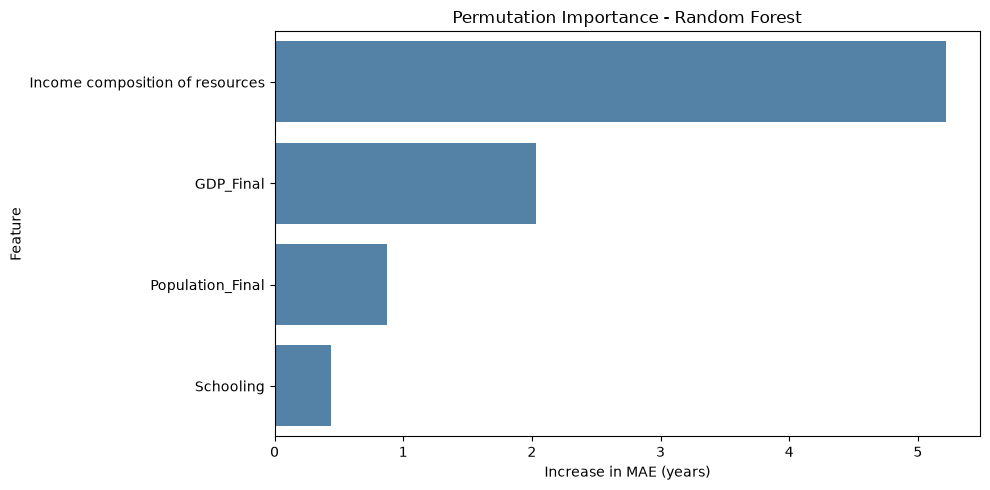

In [ ]:

from sklearn.inspection import permutation_importance

# Beräkna Permutation Importance
perm_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="neg_mean_absolute_error"
)

# Skapa tabell med resultaten
perm_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

# Sortera efter betydelse
perm_importance = perm_importance.sort_values(
    "Importance",
    ascending=False
)

# Visa resultat
display(perm_importance)

# Skapa diagram
plt.figure(figsize=(10, 5))

sns.barplot(
    data=perm_importance,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Permutation Importance - Random Forest")
plt.xlabel("Increase in MAE (years)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


### Resultat – Permutation Importance

Permutation Importance genomfördes för Random Forest-modellen för att undersöka hur mycket modellens prediktionsfel påverkas när enskilda förklarande variabler slumpmässigt blandas.

**Resultat – genomsnittlig ökning av MAE:**
- Income composition of resources: 5,22 år
- GDP_Final: 2,03 år
- Population_Final: 0,87 år
- Schooling: 0,44 år

Resultatet visar att Income composition of resources har störst betydelse för modellens prediktionsförmåga, följt av GDP_Final.

Resultaten överensstämmer med den tidigare analysen av Random Forests inbyggda Feature Importance, eftersom båda metoderna ger samma rangordning av variablerna.

Trots att Schooling tidigare visade en stark positiv korrelation med förväntad livslängd (r = 0,752), har den lägst betydelse i modellen. Detta kan delvis förklaras av att Schooling och Income composition of resources är starkt korrelerade (r = 0,80).

Resultaten visar modellens beroende av variablerna, inte deras kausala påverkan på livslängden. Eftersom analysen genomförts på testperioden betraktas den som explorativ.

### Residualanalys för Random Forest

För att undersöka modellens prediktionsfel genomförs en residualanalys.

Residualerna beräknas som skillnaden mellan verklig och predikterad förväntad livslängd.

Syftet är att undersöka om modellen systematiskt över- eller underskattar livslängden och om prediktionsfelen varierar beroende på nivån på den förväntade livslängden.

Residualanalysen används även för att identifiera observationer med stora avvikelser som kan behöva undersökas vidare.

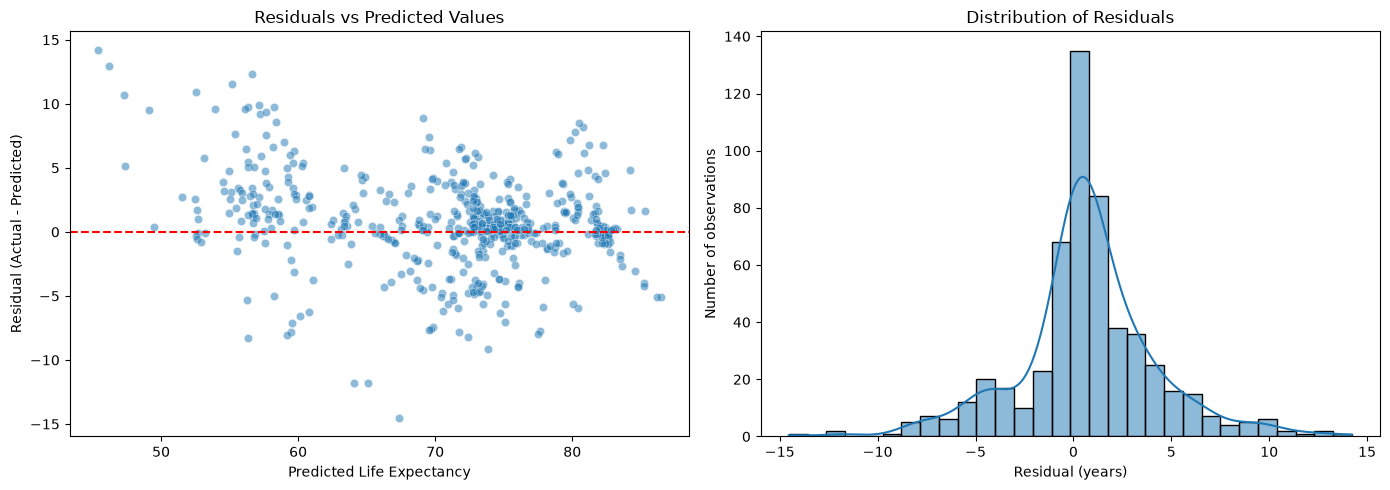

In [ ]:

# Beräkna residualer för Random Forest
residuals_rf = y_test.to_numpy() - y_pred_rf

# Skapa två diagram
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Diagram 1: Residualer mot predikterade värden
sns.scatterplot(
    x=y_pred_rf,
    y=residuals_rf,
    alpha=0.5,
    ax=axes[0]
)

axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Residuals vs Predicted Values")
axes[0].set_xlabel("Predicted Life Expectancy")
axes[0].set_ylabel("Residual (Actual - Predicted)")

# Diagram 2: Fördelning av residualer
sns.histplot(
    residuals_rf,
    bins=30,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Distribution of Residuals")
axes[1].set_xlabel("Residual (years)")
axes[1].set_ylabel("Number of observations")

plt.tight_layout()
plt.show()


### Resultat – Residualanalys för Random Forest

Residualanalysen genomfördes på testperioden 2013–2015 för att undersöka skillnader mellan verklig och predikterad förväntad livslängd.

Spridningsdiagrammet visar att många residualer ligger nära noll, vilket innebär att modellen ofta ger prediktioner som ligger nära de verkliga värdena.

Samtidigt förekommer större positiva och negativa residualer. Spridningen verkar vara större för vissa lägre predikterade livslängder, vilket kan tyda på att modellens precision varierar mellan olika grupper av observationer.

Histogrammet visar att residualerna är koncentrerade kring noll men har svansar åt båda håll. Detta innebär att modellen fortfarande gör enstaka stora prediktionsfel.

Resultaten visar att Random Forest har relativt god prediktionsförmåga, men att modellen behöver undersökas ytterligare för att identifiera vilka observationer som orsakar de största felen.

### Analys av de största prediktionsfelen

För att undersöka Random Forest-modellens begränsningar identifieras de observationer som har störst absolut prediktionsfel.

För varje observation jämförs den verkliga förväntade livslängden med modellens prediktion. Residualen och det absoluta felet beräknas.

Syftet är att identifiera om vissa länder eller tidsperioder är särskilt svåra för modellen att uppskatta.

Resultaten används för att förstå modellens svagheter och diskutera möjliga förbättringar.

In [ ]:

# Skapa en tabell med testperiodens resultat
error_analysis = test_df[
    ["Country", "Year", "Life expectancy"]
].copy()

# Lägg till modellens prediktioner
error_analysis["Predicted"] = y_pred_rf

# Beräkna residualer
error_analysis["Residual"] = (
    error_analysis["Life expectancy"] -
    error_analysis["Predicted"]
)

# Beräkna absoluta fel
error_analysis["Absolute_Error"] = (
    error_analysis["Residual"].abs()
)

# Visa de 15 största prediktionsfelen
display(
    error_analysis.sort_values(
        "Absolute_Error",
        ascending=False
    ).head(15).round(2)
)


,Country,Year,Life expectancy,Predicted,Residual,Absolute_Error
433,Côte d'Ivoire,2014,52.8,67.34,-14.54,14.54
416,Burundi,2015,59.6,45.38,14.22,14.22
417,Burundi,2014,59.1,46.17,12.93,12.93
1879,Niger,2013,69.0,56.64,12.36,12.36
434,Côte d'Ivoire,2013,52.3,64.08,-11.78,11.78
432,Côte d'Ivoire,2015,53.3,65.07,-11.77,11.77
2249,Senegal,2015,66.7,55.16,11.54,11.54
753,Djibouti,2015,63.5,52.56,10.94,10.94
513,Central African Republic,2014,58.0,47.29,10.71,10.71
2779,United Republic of Tanzania,2014,67.0,57.11,9.89,9.89


### Resultat – Analys av de största prediktionsfelen

Analysen av Random Forest-modellens största prediktionsfel visar att vissa observationer avviker betydligt från modellens genomsnittliga fel på 2,51 år.

De största felen identifierades bland annat i Côte d'Ivoire, Burundi och Niger.

För Côte d'Ivoire år 2014 överskattade modellen livslängden med 14,54 år, medan modellen underskattade livslängden i Burundi år 2015 med 14,22 år.

Flera länder förekommer vid upprepade tillfällen bland de största prediktionsfelen. Detta tyder på att modellen kan ha systematiska svårigheter att uppskatta livslängden för vissa länder.

Möjliga förklaringar kan vara att de fyra utvalda variablerna inte fångar alla relevanta hälsorelaterade och socioekonomiska förhållanden.

Resultaten visar att en modell kan ha god genomsnittlig prediktionsförmåga men samtidigt göra stora fel för enskilda observationer. Därför behövs ytterligare validering och analys innan modellen används för praktiska prognoser.

###  Genomsnittligt prediktionsfel per land

För att undersöka om Random Forest-modellen presterar olika bra för olika länder beräknas genomsnittligt absolut prediktionsfel (MAE) per land.

Analysen bygger på testperioden 2013–2015.

Syftet är att identifiera länder där modellen systematiskt har svårt att uppskatta förväntad livslängd.

Antalet observationer per land redovisas eftersom testperioden är kort och resultaten för enskilda länder därför kan vara osäkra.

,Country,MAE,Number_of_Observations,Mean_Residual
43,Côte d'Ivoire,12.70,3,-12.70
26,Burundi,12.21,3,12.21
140,Senegal,9.00,3,9.00
134,Rwanda,8.97,3,8.97
37,Congo,8.39,3,-8.39
47,Djibouti,8.34,3,8.34
3,Angola,7.67,3,-7.67
117,Niger,7.64,3,7.64
63,Ghana,7.56,3,-7.56
84,Kazakhstan,7.21,3,-7.21


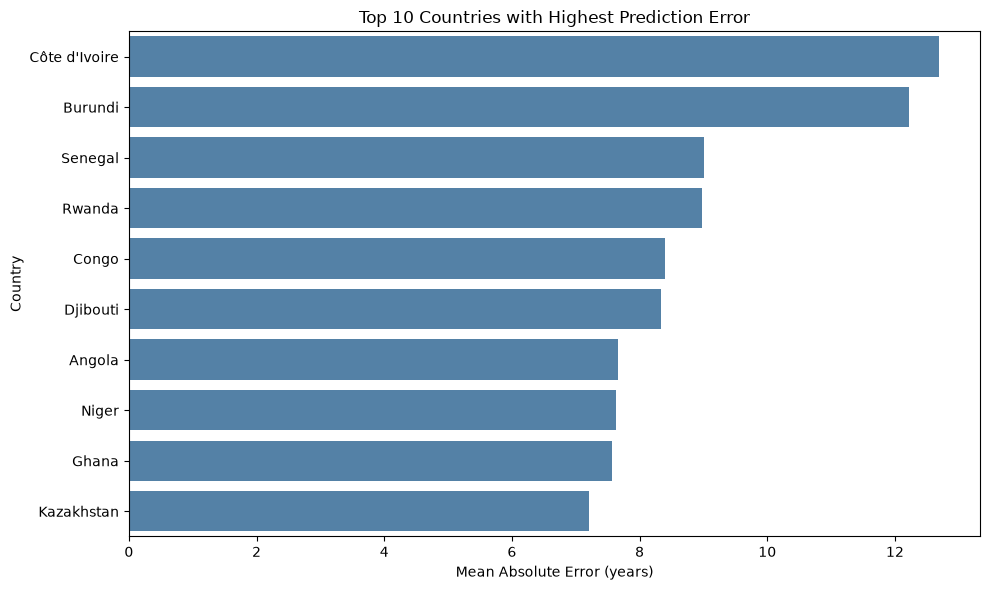

In [ ]:

# Beräkna genomsnittligt fel per land
country_errors = error_analysis.groupby("Country").agg(
    MAE=("Absolute_Error", "mean"),
    Number_of_Observations=("Absolute_Error", "count"),
    Mean_Residual=("Residual", "mean")
).reset_index()

# Sortera länder efter störst genomsnittligt fel
country_errors = country_errors.sort_values(
    "MAE",
    ascending=False
)

# Visa de 10 länderna med störst fel
display(country_errors.head(10).round(2))

# Skapa diagram
plt.figure(figsize=(10, 6))

sns.barplot(
    data=country_errors.head(10),
    x="MAE",
    y="Country",
    color="steelblue"
)

plt.title("Top 10 Countries with Highest Prediction Error")
plt.xlabel("Mean Absolute Error (years)")
plt.ylabel("Country")

plt.tight_layout()
plt.show()


### Resultat – Prediktionsfel per land

Analysen visar att Random Forest-modellens prediktionsfel varierar mellan olika länder.

De högsta genomsnittliga absoluta felen identifierades i Côte d'Ivoire (12,70 år), Burundi (12,21 år) och Senegal (9,00 år).

Côte d'Ivoire och Congo hade negativa medelresidualer, vilket innebär att modellen tenderade att överskatta livslängden i dessa länder.

Burundi, Senegal och Rwanda hade positiva medelresidualer, vilket innebär att modellen tenderade att underskatta livslängden.

Resultaten tyder på att modellen kan ha systematiska svårigheter med vissa länder. En möjlig förklaring är att de valda socioekonomiska variablerna inte fångar alla relevanta förhållanden.

Eftersom analysen bygger på endast tre observationer per land är resultaten osäkra och behöver tolkas försiktigt.

Detta motiverar ytterligare validering och undersökning av modellens generaliseringsförmåga.

### Tidsbaserad tränings- och valideringsuppdelning

För att förbättra metodiken delas perioden 2000–2012 upp i två delar:

- Träningsperiod: 2000–2009
- Valideringsperiod: 2010–2012

Träningsperioden används för att träna modellerna, medan valideringsperioden används för att jämföra algoritmer och välja modellparametrar.

Perioden 2013–2015 har redan använts för explorativ modellutvärdering och felanalys och betraktas därför inte längre som ett helt oberoende sluttest.

Denna uppdelning gör det möjligt att genomföra fortsatt modellutveckling utan att använda information från senare år i själva träningsprocessen.

In [ ]:

# Steg 43 - Ny tidsbaserad uppdelning

# Träningsperiod
train_new = df_ml[
    df_ml["Year"] <= 2009
].copy()

# Valideringsperiod
validation = df_ml[
    (df_ml["Year"] >= 2010) &
    (df_ml["Year"] <= 2012)
].copy()

# Tidigare testperiod (redan analyserad)
test_new = df_ml[
    df_ml["Year"] >= 2013
].copy()

# Skapa X och y
X_train_new = train_new[features]
y_train_new = train_new["Life expectancy"]

X_val = validation[features]
y_val = validation["Life expectancy"]

X_test_new = test_new[features]
y_test_new = test_new["Life expectancy"]

# Kontrollera antal observationer
print("Träning:", len(train_new))
print("Validering:", len(validation))
print("Tidigare testperiod:", len(test_new))

# Kontrollera att perioderna inte överlappar
print("Överlappande år:",
      set(train_new["Year"]) & set(validation["Year"]))


Träning: 1830
Validering: 549
Tidigare testperiod: 549
Överlappande år: set()


### Resultat – Tidsbaserad uppdelning

Datasetet delades upp i tre tidsperioder för att möjliggöra en mer strukturerad modellvalidering.

- Träningsperiod 2000–2009: 1 830 observationer
- Valideringsperiod 2010–2012: 549 observationer
- Tidigare testperiod 2013–2015: 549 observationer

Kontrollen visade att tränings- och valideringsperioderna inte innehåller några överlappande år.

Den nya uppdelningen gör det möjligt att träna modeller på äldre observationer och jämföra deras prediktionsförmåga på efterföljande år.

Eftersom testperioden 2013–2015 redan har använts för modelljämförelse och felanalys betraktas den som en tidigare explorativ utvärdering och inte som ett helt oberoende sluttest.

### Modelljämförelse på valideringsdata

För att jämföra modellernas generaliseringsförmåga tränas fyra regressionsmodeller på perioden 2000–2009:

- DummyRegressor (Baseline)
- Linear Regression
- Random Forest Regressor
- Gradient Boosting Regressor

Samtliga modeller utvärderas på valideringsperioden 2010–2012 med MAE, RMSE och R².

Samma förklarande variabler används för alla modeller. Saknade värden hanteras med medianimputering som anpassas endast på träningsdatan.

Syftet är att undersöka vilken metod som presterar bäst på en separat valideringsperiod och därmed ge ett bättre underlag för modellvalet.

In [ ]:

from sklearn.base import clone
from sklearn.dummy import DummyRegressor

# Modeller som ska jämföras
models = {
    "Baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": clone(linear_model),
    "Random Forest": clone(rf_model),
    "Gradient Boosting": clone(gb_model)
}

# Lista för att spara resultaten
validation_results = []

# Träna och utvärdera varje modell
for name, model in models.items():

    # Träna på 2000–2009
    model.fit(X_train_new, y_train_new)

    # Prediktera 2010–2012
    predictions = model.predict(X_val)

    # Beräkna utvärderingsmått
    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    r2 = r2_score(y_val, predictions)

    validation_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Skapa en jämförelsetabell
validation_df = pd.DataFrame(validation_results)

# Sortera efter lägst MAE
validation_df = validation_df.sort_values("MAE")

display(validation_df.round(3))


,Model,MAE,RMSE,R2
2,Random Forest,2.313,3.366,0.858
3,Gradient Boosting,2.771,3.782,0.820
1,Linear Regression,4.009,5.272,0.651
0,Baseline,7.876,9.230,-0.071


### Resultat – Modelljämförelse på valideringsdata

Fyra modeller tränades på data från perioden 2000–2009 och utvärderades på valideringsperioden 2010–2012.

**Resultat:**

| Modell | MAE | RMSE | R² |
|---|---:|---:|---:|
| Random Forest | 2,313 | 3,366 | 0,858 |
| Gradient Boosting | 2,771 | 3,782 | 0,820 |
| Linear Regression | 4,009 | 5,272 | 0,651 |
| Baseline | 7,876 | 9,230 | −0,071 |

Random Forest uppnådde bäst resultat med lägst MAE och RMSE samt högst R².

Jämfört med Gradient Boosting hade Random Forest cirka 16,5 % lägre MAE. Jämfört med Linear Regression var felet cirka 42,3 % lägre.

Resultatet stödjer tidigare observationer om att Random Forest är en lämplig metod för att uppskatta förväntad livslängd utifrån de valda variablerna.

Eftersom senare testdata redan har analyserats betraktas resultaten som en del av en explorativ modellutvärdering, inte som en helt oberoende slutlig utvärdering.

Nästa steg är att undersöka om Random Forest kan förbättras genom hyperparameteroptimering.

### Steg 45 – Hyperparameteroptimering av Random Forest

Random Forest har hittills gett bäst prediktionsresultat vid modelljämförelsen.

För att undersöka om modellen kan förbättras testas olika kombinationer av hyperparametrar:

- **n_estimators:** Antalet beslutsträd i modellen.
- **max_depth:** Maximalt djup för beslutsträden.
- **min_samples_leaf:** Minsta antal observationer i ett löv.

Samtliga modeller tränas på perioden 2000–2009 och utvärderas på valideringsperioden 2010–2012.

MAE används som huvudsakligt utvärderingsmått. Den hyperparameterkombination som ger lägst MAE väljs för fortsatt modellutveckling.

Saknade värden hanteras med medianimputering i en Pipeline, där imputeringen endast anpassas på träningsdatan för att undvika dataläckage.

In [ ]:

from itertools import product
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error
import pandas as pd

# Hyperparametrar som ska testas
n_estimators_options = [100, 200]
max_depth_options = [5, 10, None]
min_samples_leaf_options = [1, 3, 5]

# Lista för att spara resultaten
tuning_results = []

# Testa alla kombinationer
for n, depth, leaf in product(
    n_estimators_options,
    max_depth_options,
    min_samples_leaf_options
):

    # Skapa Random Forest-modell
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=n,
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=42,
            n_jobs=-1
        ))
    ])

    # Träna modellen
    model.fit(X_train_new, y_train_new)

    # Gör prediktioner på valideringsdata
    predictions = model.predict(X_val)

    # Beräkna MAE
    mae = mean_absolute_error(y_val, predictions)

    # Spara resultatet
    tuning_results.append({
        "n_estimators": n,
        "max_depth": depth,
        "min_samples_leaf": leaf,
        "MAE": mae
    })

# Skapa resultattabell
tuning_df = pd.DataFrame(tuning_results)

# Sortera efter lägst MAE
tuning_df = tuning_df.sort_values(
    "MAE"
).reset_index(drop=True)

# Visa de fem bästa kombinationerna
display(tuning_df.head(5).round(3))


,n_estimators,max_depth,min_samples_leaf,MAE
0,200,NaN,1,2.313
1,100,NaN,1,2.320
2,100,10.0,1,2.356
3,200,10.0,1,2.360
4,200,NaN,3,2.396


### Resultat – Hyperparameteroptimering av Random Forest

Totalt testades 18 olika kombinationer av hyperparametrar för Random Forest Regressor.

Modellerna tränades på perioden 2000–2009 och utvärderades på valideringsperioden 2010–2012.

Den bästa kombinationen var:
- n_estimators = 200
- max_depth = None (obegränsat djup)
- min_samples_leaf = 1

Denna kombination uppnådde MAE = 2,313 år.

Resultatet motsvarar den tidigare Random Forest-modellen, vilket innebär att hyperparameteroptimeringen inte förbättrade prediktionsförmågan inom det undersökta parameterintervallet.

Eftersom den ursprungliga modellen redan gav bäst resultat behålls samma inställningar för den fortsatta modellutvecklingen.

Resultatet visar att mer komplex parameterjustering inte alltid leder till bättre prediktionsförmåga.

### Steg 46 – Träning av vald Random Forest-modell

Efter jämförelse av regressionsmodeller och hyperparameteroptimering valdes Random Forest med 200 beslutsträd, obegränsat maxdjup och min_samples_leaf = 1.

Modellen tränas nu på samtliga observationer från perioden 2000–2012.

Saknade värden hanteras med SimpleImputer, där medianvärden beräknas från träningsdatan.

Syftet är att skapa en modell som senare kan användas för prediktioner i en Streamlit-applikation.

Perioden 2013–2015 har redan använts för explorativ modellutvärdering och betraktas därför inte som ett helt oberoende sluttest.

In [ ]:

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Skapa vald Random Forest-modell
final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

# Träna modellen på 2000–2012
final_model.fit(X_train, y_train)

print("Vald Random Forest-modell har tränats!")
print("Antal träningsobservationer:", len(X_train))
print("Antal variabler:", X_train.shape[1])


Vald Random Forest-modell har tränats!
Antal träningsobservationer: 2379
Antal variabler: 4


### Steg 47 – Spara den tränade maskininlärningsmodellen

Efter modelljämförelse och hyperparameteroptimering har Random Forest valts för fortsatt utveckling.

Modellen har tränats på 2 379 observationer från perioden 2000–2012 med fyra förklarande variabler.

För att kunna använda modellen i en Streamlit-applikation sparas den med hjälp av biblioteket joblib.

Den sparade modellen innehåller både medianimputering och den tränade Random Forest-modellen genom en Pipeline.

Det gör att applikationen kan läsa in modellen och skapa prediktioner utan att träningen behöver genomföras igen.

Modellen uppskattar förväntad livslängd utifrån tillgängliga socioekonomiska indikatorer och ska inte tolkas som en säker prognos för framtida år.

In [ ]:

import joblib
from pathlib import Path

# Skapa en mapp för tränade modeller
model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

# Spara modellen
model_path = model_dir / "life_expectancy_rf.joblib"

joblib.dump(final_model, model_path)

# Kontrollera att filen finns
print("Modellen sparad:", model_path.resolve())
print("Filen finns:", model_path.exists())


Modellen sparad: C:\Users\milen\source\repos\Statistisk_programmering_ML\models\life_expectancy_rf.joblib
Filen finns: True


In [ ]:

# Läs in den sparade modellen
loaded_model = joblib.load(
    "models/life_expectancy_rf.joblib"
)

# Testa prediktion på en befintlig observation
sample = X_test.iloc[[0]]

prediction = loaded_model.predict(sample)

print(
    "Predikterad livslängd:",
    round(prediction[0], 2),
    "år"
)


Predikterad livslängd: 59.6 år


### Steg 48 – Export av bearbetad data till Streamlit

För att kunna använda det berikade datasetet i en interaktiv Streamlit-applikation exporteras den bearbetade datan till en CSV-fil.

Datasetet innehåller historiska WHO-uppgifter tillsammans med BNP per capita och befolkningsstatistik från World Bank API.

Filen används för att visa historiska trender, jämföra länder och presentera statistiska samband.

Maskininlärningsmodellen sparas separat som en joblib-fil och används för att uppskatta förväntad livslängd utifrån fyra socioekonomiska indikatorer.

De ursprungliga datakällorna behålls för spårbarhet. Appens prediktioner är modellbaserade uppskattningar och ska inte tolkas som säkra framtidsprognoser.

In [ ]:

from pathlib import Path

# Skapa en separat mapp för Life Expectancy-data
data_dir = Path("life_data")
data_dir.mkdir(exist_ok=True)

# Spara det bearbetade datasetet
data_path = data_dir / "life_expectancy_enriched.csv"

df_final.to_csv(data_path, index=False)

# Kontrollera att filen finns
print("Data sparad:", data_path.resolve())
print("Filen finns:", data_path.exists())
print("Antal rader:", len(df_final))


Data sparad: C:\Users\milen\source\repos\Statistisk_programmering_ML\life_data\life_expectancy_enriched.csv
Filen finns: True
Antal rader: 2938



##  Tidsbaserad Cross-validation

För att utvärdera Random Forest-modellens stabilitet används
en tidsbaserad cross-validation med fem valideringsperioder.

Modellen tränas på historiska data och utvärderas på
nästkommande år. Träningsperioden utökas successivt.

Fem valideringsår används: 2008, 2009, 2010, 2011 och 2012.

Resultaten utvärderas med:
- MAE – Mean Absolute Error
- RMSE – Root Mean Squared Error
- R² – förklaringsgrad

Denna metod används för att minska risken för att framtida
observationer påverkar modellens träning och för att undersöka
hur väl modellen generaliserar över olika tidsperioder.


In [ ]:

# ============================================
# STEG 48 – TIDSBASERAD CROSS-VALIDATION
# ============================================

import pandas as pd
import numpy as np

from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Hitta projektets huvudmapp
data_path = Path("life_data/life_expectancy_enriched.csv")

if not data_path.exists():
    raise FileNotFoundError(
        "Hittar inte life_data/life_expectancy_enriched.csv. "
        "Öppna projektets huvudmapp i VS Code."
    )

df_cv = pd.read_csv(data_path)

features_cv = [
    "Schooling",
    "Income composition of resources",
    "GDP_Final",
    "Population_Final"
]

target_cv = "Life expectancy"

required = ["Year", target_cv] + features_cv

missing = [c for c in required if c not in df_cv.columns]
if missing:
    raise ValueError(f"Kolumner saknas: {missing}")

# Säkerställ rätt datatyper
for col in required:
    df_cv[col] = pd.to_numeric(
        df_cv[col], errors="coerce"
    )

# Målvariabeln och år måste vara tillgängliga
df_cv = df_cv.dropna(
    subset=["Year", target_cv]
).copy()

# Vi använder enbart historiska år till och med 2012
df_cv = df_cv[
    df_cv["Year"].between(2000, 2012)
].copy()

results_cv = []

# Fem tidsbaserade foldar
for validation_year in range(2008, 2013):

    train = df_cv[
        df_cv["Year"] < validation_year
    ].copy()

    validation = df_cv[
        df_cv["Year"] == validation_year
    ].copy()

    if train.empty or validation.empty:
        raise ValueError(
            f"Data saknas för fold {validation_year}"
        )

    X_train = train[features_cv]
    y_train = train[target_cv]

    X_val = validation[features_cv]
    y_val = validation[target_cv]

    # Ny pipeline i varje fold för att undvika
    # att imputering använder valideringsdata
    model_cv = Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "random_forest",
            RandomForestRegressor(
                n_estimators=200,
                max_depth=None,
                min_samples_leaf=1,
                random_state=42,
                n_jobs=-1
            )
        )
    ])

    model_cv.fit(X_train, y_train)

    predictions = model_cv.predict(X_val)

    mae = mean_absolute_error(
        y_val, predictions
    )

    rmse = np.sqrt(
        mean_squared_error(y_val, predictions)
    )

    r2 = r2_score(
        y_val, predictions
    )

    results_cv.append({
        "Valideringsår": validation_year,
        "Träningsperiod": (
            f"2000–{validation_year - 1}"
        ),
        "Antal träning": len(train),
        "Antal validering": len(validation),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

cv_results = pd.DataFrame(results_cv)

display(
    cv_results.round(3)
)

print("\nGENOMSNITTLIGA RESULTAT")

print(
    f"MAE: {cv_results['MAE'].mean():.3f} år"
)

print(
    f"RMSE: {cv_results['RMSE'].mean():.3f} år"
)

print(
    f"R²: {cv_results['R2'].mean():.3f}"
)

print(
    f"MAE standardavvikelse: "
    f"{cv_results['MAE'].std():.3f} år"
)


,Valideringsår,Träningsperiod,Antal träning,Antal validering,MAE,RMSE,R2
0,2008,2000–2007,1464,183,1.957,3.099,0.886
1,2009,2000–2008,1647,183,1.747,2.657,0.912
2,2010,2000–2009,1830,183,1.842,3.092,0.889
3,2011,2000–2010,2013,183,2.081,2.934,0.891
4,2012,2000–2011,2196,183,1.869,2.739,0.897



GENOMSNITTLIGA RESULTAT
MAE: 1.899 år
RMSE: 2.904 år
R²: 0.895
MAE standardavvikelse: 0.126 år


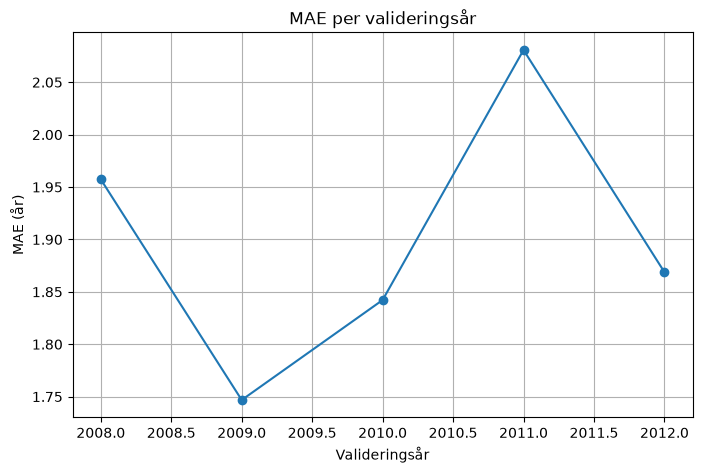

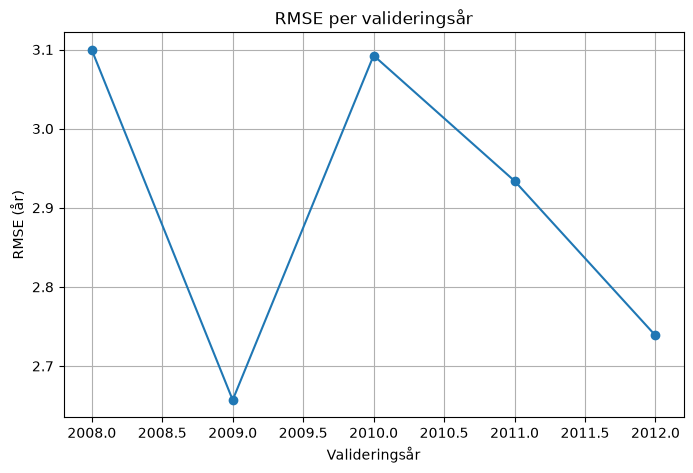

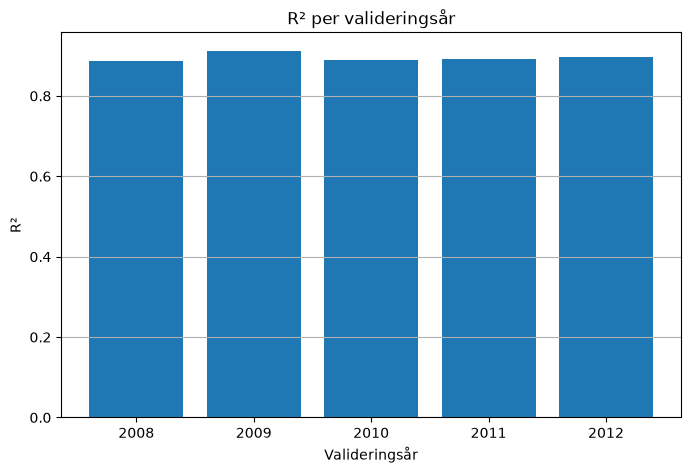

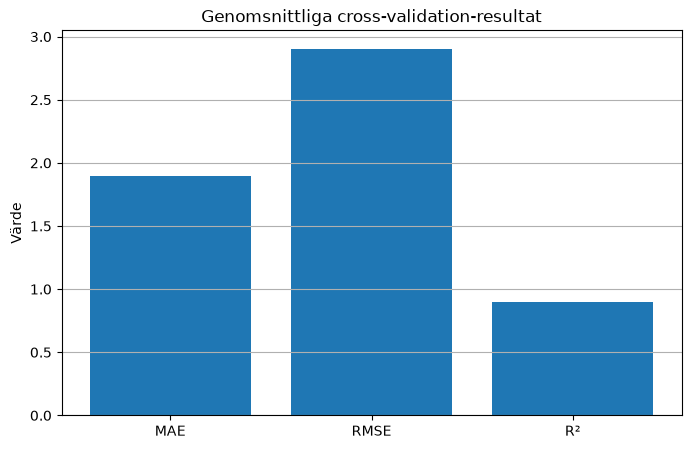

In [ ]:
import matplotlib.pyplot as plt

# Säkerställ att resultaten är sorterade i rätt ordning
cv_plot = cv_results.sort_values("Valideringsår").copy()

# =========================
# Diagram 1 – MAE per år
# =========================
plt.figure(figsize=(8, 5))
plt.plot(cv_plot["Valideringsår"], cv_plot["MAE"], marker="o")
plt.title("MAE per valideringsår")
plt.xlabel("Valideringsår")
plt.ylabel("MAE (år)")
plt.grid(True)
plt.show()

# =========================
# Diagram 2 – RMSE per år
# =========================
plt.figure(figsize=(8, 5))
plt.plot(cv_plot["Valideringsår"], cv_plot["RMSE"], marker="o")
plt.title("RMSE per valideringsår")
plt.xlabel("Valideringsår")
plt.ylabel("RMSE (år)")
plt.grid(True)
plt.show()

# =========================
# Diagram 3 – R² per år
# =========================
plt.figure(figsize=(8, 5))
plt.bar(cv_plot["Valideringsår"], cv_plot["R2"])
plt.title("R² per valideringsår")
plt.xlabel("Valideringsår")
plt.ylabel("R²")
plt.grid(True, axis="y")
plt.show()

# =========================
# Diagram 4 – Genomsnittliga resultat
# =========================
avg_mae = cv_plot["MAE"].mean()
avg_rmse = cv_plot["RMSE"].mean()
avg_r2 = cv_plot["R2"].mean()

summary_df = {
    "Mått": ["MAE", "RMSE", "R²"],
    "Värde": [avg_mae, avg_rmse, avg_r2]
}

plt.figure(figsize=(8, 5))
plt.bar(summary_df["Mått"], summary_df["Värde"])
plt.title("Genomsnittliga cross-validation-resultat")
plt.ylabel("Värde")
plt.grid(True, axis="y")
plt.show()

### Tolkning av cross-validation

Cross-validation-resultaten visar att Random Forest-modellen
är stabil över olika valideringsår.

MAE varierar mellan 1.747 och 2.081 år, vilket innebär att
modellens prediktioner i genomsnitt ligger ungefär 1.9 år från
det faktiska värdet.

RMSE varierar mellan 2.657 och 3.099 år, vilket visar att även
större fel är relativt begränsade.

R²-värdena ligger mellan 0.886 och 0.912, vilket innebär att
modellen förklarar en stor del av variationen i livslängd.

Sammantaget tyder resultaten på att modellen generaliserar väl
över tid och inte bara fungerar för en enskild testperiod.


## Feature Engineering utifrån EDA

I den explorativa dataanalysen undersöktes sambandet mellan BNP
per capita och förväntad livslängd.

BNP per capita varierar kraftigt mellan länder och har en
sned fördelning. För att undersöka om denna skevhet påverkar
modellens resultat skapas en ny variabel: GDP_Log.

GDP_Log beräknas med log1p, vilket motsvarar ln(1 + BNP).
Transformationen minskar skillnaderna mellan mycket höga
värden och kan göra sambanden lättare att analysera.

Den nya variabeln jämförs med den ursprungliga GDP_Final.
Vi testar även om GDP_Log förbättrar Random Forest-modellens
prediktionsförmåga genom tidsbaserad cross-validation.


NY FEATURE: GDP_Log
Antal giltiga värden: 2908


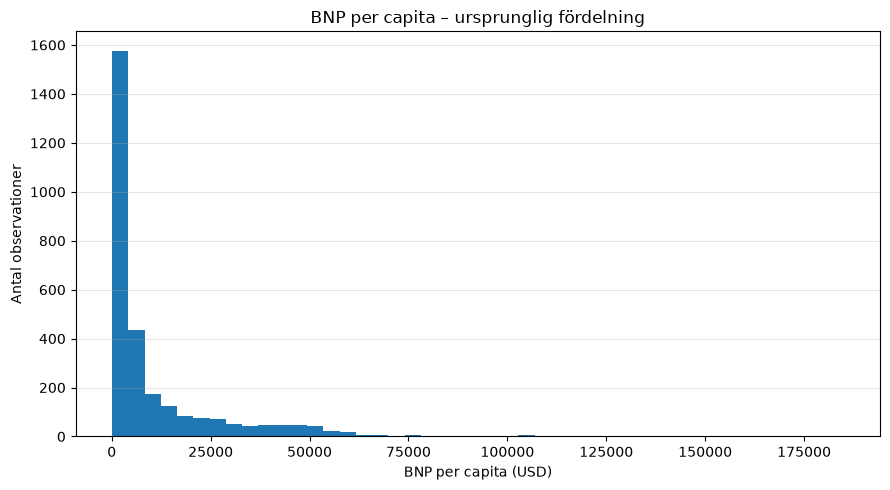

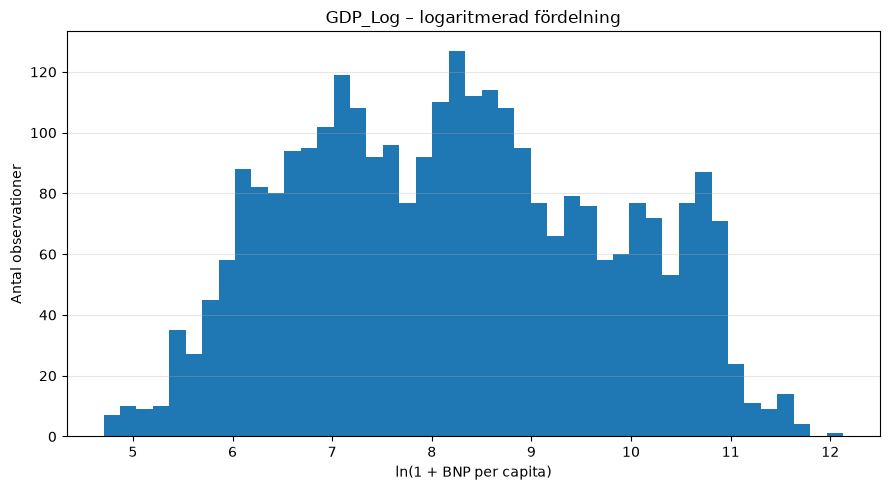

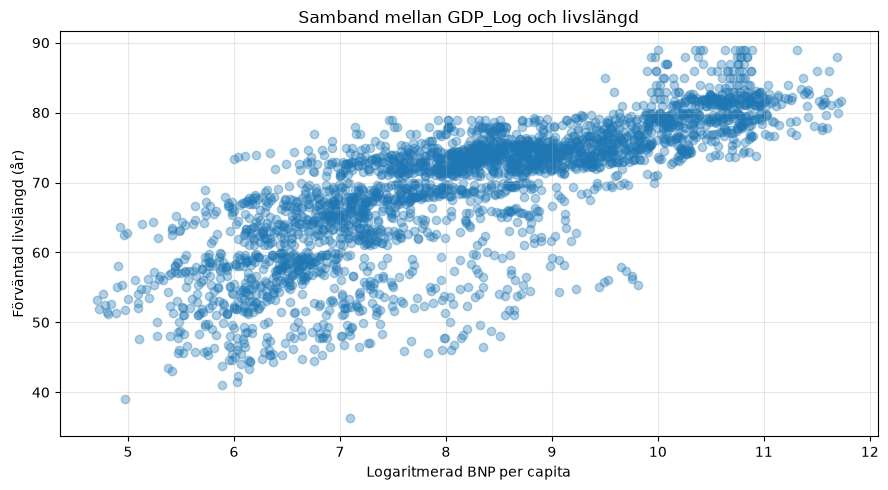

Modell,Original – 4 variabler,Utökad – 5 variabler
Valideringsår,,
2008,1.957,1.967
2009,1.747,1.762
2010,1.842,1.852
2011,2.081,2.085
2012,1.869,1.864



GENOMSNITTLIG MAE
Original – 4 variabler: 1.899 år
Utökad – 5 variabler: 1.906 år


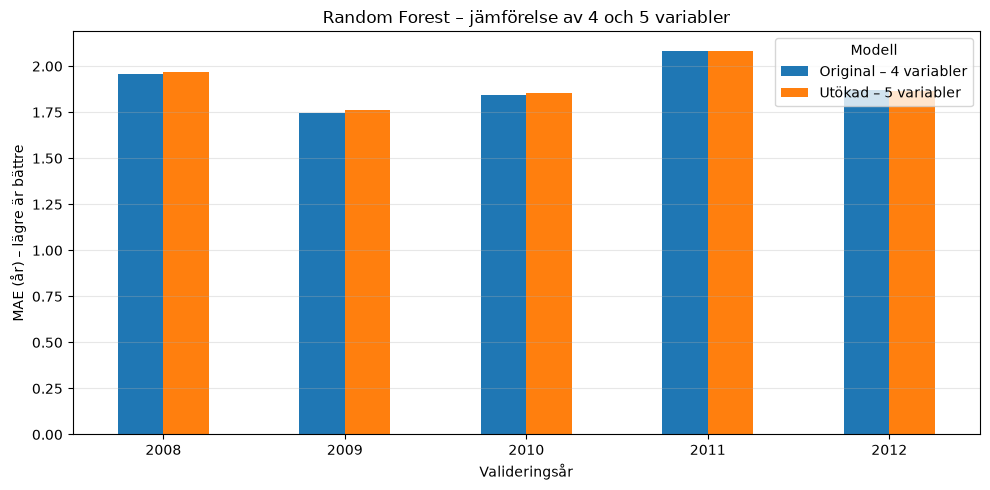


SLUTSATS
Den ursprungliga modellen gav lägre genomsnittlig MAE i denna jämförelse.
Skillnad (utökad minus original): +0.007 år


In [ ]:

# ==================================================
# STEG 49 – FEATURE ENGINEERING: GDP_LOG
# ==================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# 1. Läs befintliga data
path = Path("life_data/life_expectancy_enriched.csv")

data_fe = pd.read_csv(path)

original_features = [
    "Schooling",
    "Income composition of resources",
    "GDP_Final",
    "Population_Final"
]

target = "Life expectancy"

required = ["Year", target] + original_features

for col in required:
    data_fe[col] = pd.to_numeric(
        data_fe[col], errors="coerce"
    )

# 2. Skapa ny feature
# Negativa BNP-värden betraktas som ogiltiga
gdp_valid = data_fe["GDP_Final"].where(
    data_fe["GDP_Final"] >= 0
)

data_fe["GDP_Log"] = np.log1p(gdp_valid)

print("NY FEATURE: GDP_Log")
print("Antal giltiga värden:", data_fe["GDP_Log"].notna().sum())

# 3. Visualisera BNP före transformation
plt.figure(figsize=(9, 5))

plt.hist(
    data_fe["GDP_Final"].dropna(),
    bins=45
)

plt.title("BNP per capita – ursprunglig fördelning")
plt.xlabel("BNP per capita (USD)")
plt.ylabel("Antal observationer")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Visualisera BNP efter transformation
plt.figure(figsize=(9, 5))

plt.hist(
    data_fe["GDP_Log"].dropna(),
    bins=45
)

plt.title("GDP_Log – logaritmerad fördelning")
plt.xlabel("ln(1 + BNP per capita)")
plt.ylabel("Antal observationer")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Visualisera samband med livslängd
plot_data = data_fe.dropna(
    subset=["GDP_Log", target]
)

plt.figure(figsize=(9, 5))

plt.scatter(
    plot_data["GDP_Log"],
    plot_data[target],
    alpha=0.35
)

plt.title("Samband mellan GDP_Log och livslängd")
plt.xlabel("Logaritmerad BNP per capita")
plt.ylabel("Förväntad livslängd (år)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Jämför två Random Forest-modeller
# med samma tidsbaserade valideringsperioder

extended_features = original_features + ["GDP_Log"]

comparison = []

for validation_year in range(2008, 2013):

    training = data_fe[
        (data_fe["Year"] >= 2000) &
        (data_fe["Year"] < validation_year)
    ].dropna(subset=[target])

    validation = data_fe[
        data_fe["Year"] == validation_year
    ].dropna(subset=[target])

    if training.empty or validation.empty:
        raise ValueError(
            f"Data saknas för år {validation_year}"
        )

    for model_name, features in [
        ("Original – 4 variabler", original_features),
        ("Utökad – 5 variabler", extended_features)
    ]:

        pipeline = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(
                n_estimators=200,
                max_depth=None,
                min_samples_leaf=1,
                random_state=42,
                n_jobs=-1
            ))
        ])

        pipeline.fit(
            training[features],
            training[target]
        )

        predictions = pipeline.predict(
            validation[features]
        )

        comparison.append({
            "Valideringsår": validation_year,
            "Modell": model_name,
            "MAE": mean_absolute_error(
                validation[target],
                predictions
            )
        })

comparison_df = pd.DataFrame(comparison)

# 7. Resultattabell
comparison_pivot = comparison_df.pivot(
    index="Valideringsår",
    columns="Modell",
    values="MAE"
)

display(comparison_pivot.round(3))

print("\nGENOMSNITTLIG MAE")

means = comparison_df.groupby("Modell")["MAE"].mean()

for name, value in means.items():
    print(f"{name}: {value:.3f} år")

# 8. Visualisera modelljämförelsen
ax = comparison_pivot.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_title("Random Forest – jämförelse av 4 och 5 variabler")
ax.set_xlabel("Valideringsår")
ax.set_ylabel("MAE (år) – lägre är bättre")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# 9. Automatisk slutsats
original_mae = means["Original – 4 variabler"]
extended_mae = means["Utökad – 5 variabler"]

print("\nSLUTSATS")

if extended_mae < original_mae:
    print(
        "Modellen med GDP_Log gav lägre genomsnittlig "
        "MAE i denna jämförelse."
    )
elif extended_mae > original_mae:
    print(
        "Den ursprungliga modellen gav lägre genomsnittlig "
        "MAE i denna jämförelse."
    )
else:
    print(
        "Modellerna gav samma genomsnittliga MAE."
    )

print(
    f"Skillnad (utökad minus original): "
    f"{extended_mae - original_mae:+.3f} år"
)



###  Resultat och slutsats

Utifrån den explorativa dataanalysen skapades en ny variabel,
GDP_Log, genom logaritmisk transformation av BNP per capita.

Syftet var att minska effekten av BNP-variabelns sneda
fördelning och undersöka om transformationen förbättrade
modellens prediktionsförmåga.

Två Random Forest-modeller jämfördes med fem tidsbaserade
valideringsperioder (2008–2012).

**Resultat:**

- Ursprunglig modell (4 variabler): MAE = 1,899 år
- Utökad modell (5 variabler): MAE = 1,906 år
- Skillnad: +0,007 år för den utökade modellen

Den nya variabeln förbättrade inte modellens resultat.
Skillnaden är mycket liten, men den ursprungliga modellen
uppnådde lägst genomsnittligt prediktionsfel.

Därför behålls den ursprungliga Random Forest-modellen
med fyra variabler.

Experimentet visar att ytterligare variabler inte
automatiskt leder till bättre prediktioner.

Resultatet gäller de undersökta valideringsperioderna
och innebär inte att GDP_Log saknar värde för alla
andra modeller eller dataset.



# Final Summary & Conclusions

## 1. Projektets syfte

Syftet med projektet var att undersöka vilka faktorer som
samvarierar med förväntad livslängd och utveckla en
maskininlärningsmodell som kan uppskatta livslängd
utifrån socioekonomiska variabler.

Projektet omfattar explorativ dataanalys (EDA),
databearbetning, integration av externa API-data,
feature engineering, modellträning, modellutvärdering,
cross-validation och interaktiv visualisering i Streamlit.

## 2. Dataset och datakällor

Huvuddatasetet kommer från Kaggle:
Life Expectancy (WHO).

Datasetet innehåller observationer för olika länder
under perioden 2000–2015.

För att komplettera och förbättra datakvaliteten
integrerades uppgifter från World Bank API.

Två centrala ekonomiska och demografiska variabler
bearbetades och kompletterades:

- GDP_Final – BNP per capita
- Population_Final – total befolkning

Den externa dataintegrationen förbättrade
möjligheterna att genomföra analyser och
bygga prediktionsmodeller.

## 3. Explorativ dataanalys (EDA)

EDA genomfördes med histogram, boxplots,
spridningsdiagram och korrelationsanalyser.

Analysen undersökte bland annat sambanden mellan:

- Förväntad livslängd och utbildning
- Förväntad livslängd och inkomstrelaterat index
- Förväntad livslängd och BNP per capita
- Förväntad livslängd och befolkning

Ett tydligt positivt samband observerades mellan
utbildning och förväntad livslängd.

Pearson-korrelationen mellan Schooling och
Life expectancy var cirka 0,752 i den tidigare analysen.

Det betyder att länder med högre utbildningsnivåer
ofta också har högre förväntad livslängd.

Korrelation innebär dock inte nödvändigtvis
ett orsakssamband.

## 4. Baseline och modelljämförelse

En DummyRegressor användes som enkel baseline
för att skapa en referensnivå.

Därefter undersöktes flera regressionsmodeller:

- Linear Regression
- Random Forest Regressor
- Gradient Boosting Regressor

Modellerna utvärderades med:

- MAE – Mean Absolute Error
- RMSE – Root Mean Squared Error
- R² – förklaringsgrad

Under den tidigare valideringsperioden 2010–2012
uppnåddes följande MAE-resultat:

| Modell | MAE (år) |
|---|---:|
| DummyRegressor | 7,876 |
| Linear Regression | 4,009 |
| Gradient Boosting | 2,771 |
| Random Forest | 2,313 |

Random Forest uppnådde lägst MAE av de jämförda
modellerna under denna valideringsperiod.

## 5. Tidsbaserad cross-validation

Random Forest utvärderades även med fem
tidsbaserade valideringsperioder.

Träningsperioden utökades successivt och modellen
validerades på ett efterföljande år.

Valideringsåren var 2008–2012.

### Genomsnittliga resultat

| Utvärderingsmått | Resultat |
|---|---:|
| MAE | 1,899 år |
| RMSE | 2,904 år |
| R² | 0,895 |
| MAE standardavvikelse | 0,126 år |

Resultaten visar att modellen presterade relativt
stabilt under de fem undersökta valideringsåren.

Det genomsnittliga absoluta prediktionsfelet
var cirka 1,9 år.

R² på 0,895 visar att modellen förklarade en stor
andel av variationen i livslängd inom de
undersökta valideringsperioderna.

Resultaten från cross-validation och den tidigare
valideringen är separata utvärderingar och
ska inte förväxlas.

## 6. Feature engineering

En ny variabel, GDP_Log, skapades genom att
logaritmera BNP per capita.

Syftet var att minska effekten av den sneda
fördelningen i BNP och undersöka om det
förbättrade Random Forest-modellen.

Två modeller jämfördes genom fem tidsbaserade
valideringsperioder:

| Modell | Genomsnittlig MAE |
|---|---:|
| Random Forest – 4 variabler | 1,899 år |
| Random Forest – 5 variabler | 1,906 år |

Den utökade modellen gav inte bättre resultat.

Skillnaden var liten, men den ursprungliga
modellen uppnådde lägre MAE.

Därför behölls Random Forest med fyra variabler.

Detta visar att nya variabler inte automatiskt
förbättrar modellens prediktionsförmåga.

## 7. Tolkning av modellen

Den valda Random Forest-modellen använder:

1. Schooling
2. Income composition of resources
3. GDP_Final
4. Population_Final

Tidigare feature importance-analys visade att
Income composition of resources hade störst
betydelse för modellens prediktioner.

Även GDP_Final bidrog tydligt.

Feature importance beskriver hur modellen
använder variablerna, men visar inte att
variablerna har en direkt kausal effekt
på livslängden.

## 8. Hyperparameteroptimering

Random Forest-modellen undersöktes med
olika hyperparameterkombinationer.

Optimeringen gav ingen tydlig förbättring
jämfört med den redan valda konfigurationen.

Därför behölls den tidigare modellen.

Resultatet visar vikten av att utvärdera
förändringar empiriskt i stället för att
anta att en mer komplex modell är bättre.

## 9. Streamlit-dashboard

En interaktiv dashboard utvecklades med Streamlit.

Dashboarden omfattar:

- Filtrering efter land och tidsperiod
- KPI-kort
- Historiska utvecklingsdiagram
- Världskarta med ländermarkeringar
- Ranking av länder
- Sambandsanalys mellan valbara variabler
- Visning och export av filtrerade data

En separat ML Simulator utvecklades också.

Simulatorn använder den sparade Random Forest-modellen
för att beräkna prediktioner utifrån fyra variabler.

Användaren kan jämföra två scenarier och undersöka
hur modellens prediktion förändras när en variabel
justeras.

## 10. Begränsningar

Projektet har flera viktiga begränsningar.

WHO-datasetet innehåller historiska observationer
från 2000–2015.

Vissa variabler saknar observationer för senare år.

Random Forest-modellen bygger på historiska samband
och är inte en direkt framtidsprognos.

För att förutsäga framtida livslängd behöver även
framtida värden för modellens variabler uppskattas.

Modellen kan också påverkas av datakvalitet,
saknade värden, skillnader mellan länder och
förändrade samband över tid.

Observationer från samma land under flera år
är dessutom inte oberoende.

Den tidsbaserade valideringen minskar risken
för läckage från framtida år, men innebär inte
att modellen har utvärderats på helt nya länder.

## 11. Slutsats

Projektet visar att maskininlärning kan användas
för att uppskatta förväntad livslängd baserat
på socioekonomiska faktorer.

Random Forest gav bättre resultat än de enklare
modellerna i den genomförda valideringen.

Fem tidsbaserade valideringsperioder gav en
genomsnittlig MAE på 1,899 år och R² på 0,895.

Feature engineering och hyperparameteroptimering
undersöktes systematiskt, men gav ingen ytterligare
förbättring av den valda modellen.

Den slutliga lösningen kombinerar dataanalys,
externa datakällor, maskininlärning och en
interaktiv Streamlit-dashboard.

Projektets viktigaste slutsats är att en bra
prediktionsmodell inte enbart handlar om låg
felmarginal, utan också om datakvalitet,
korrekt utvärdering, tolkbarhet och tydlig
kommunikation av modellens begränsningar.
